<a href="https://colab.research.google.com/github/dee431/-Global_Superyachts_-_Cruises_Analytics/blob/main/%F0%9F%9A%A2%F0%9F%93%88Global_Superyachts_%26_Cruises_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
thinukakusalmith06_global_superyachts_and_luxury_cruise_spatial_dataset_path = kagglehub.dataset_download('thinukakusalmith06/global-superyachts-and-luxury-cruise-spatial-dataset')

print('Data source import complete.')


Using Colab cache for faster access to the 'global-superyachts-and-luxury-cruise-spatial-dataset' dataset.
Data source import complete.


In [2]:
# ==============================================================================
# INTRODUCTION & PROBLEM FRAMING
# ==============================================================================

print("🚢" * 20)
print("🌟 GLOBAL SUPERYACHTS & CRUISES DATA SCIENCE EXPLORATION 🌟")
print("🚢" * 20 + "\n")

print("📋 [PROJECT INTRODUCTION]")
print("----------------------------------------------------------------------")
print("🌊 Welcome to the Maritime Analytics Suite!")
print("🛥️ This project performs end-to-end Exploratory Data Analysis (EDA),")
print("   Feature Engineering, Advanced Visualization, and Machine Learning")
print("   modeling on the Global Superyachts and Cruises Dataset.")
print("----------------------------------------------------------------------\n")

print("🎯 [PROBLEM STATEMENT & OBJECTIVES]")
print("----------------------------------------------------------------------")
print("💰 Target Objective : Predict 'Estimated_Value_USD_Millions' using")
print("                       vessel specs, physical dimensions, and regions.")
print("📊 Business Goal     : Help maritime brokers, insurers, and shipyards")
print("                       accurately estimate yacht values and classify")
print("                       vessel performance dynamics.")
print("🛠️ Analytical Tasks  : Comprehensive EDA, Data Cleaning, Advanced Plots")
print("                       (SHAP, LIME, Clustering, Anomalies), and Ensemble ML.")
print("----------------------------------------------------------------------\n")

print("📁 [DATASET DESCRIPTION]")
print("----------------------------------------------------------------------")
print("📄 Dataset Name     : Global_Superyachts_and_Cruises.csv")
print("🔢 Dimensions       : 9,000 Rows x 15 Columns")
print("📌 Key Features     :")
print("   • Vessel_ID                      : Unique identifier for each vessel")
print("   • Vessel_Name                    : Name of the superyacht or cruise ship")
print("   • Type                           : Category ('Superyacht', 'Luxury Cruise', etc.)")
print("   • Builder                        : Shipyard/Manufacturer name")
print("   • Year_Built                     : Year of manufacturing completion")
print("   • Length_meters                  : Overall length in meters")
print("   • Gross_Tonnage                  : Volume/Capacity unit measure")
print("   • Engine_Type                    : Propulsion system specification")
print("   • Top_Speed_knots                : Maximum recorded speed in knots")
print("   • Guests_Capacity                : Maximum passenger/guest capacity")
print("   • Crew_Capacity                  : Total crew complement onboard")
print("   • Estimated_Value_USD_Millions   : [TARGET Variable] Valuation in $M")
print("   • Current_Region                 : Geographic operational zone")
print("   • Latitude / Longitude           : GPS coordinates of current position")
print("----------------------------------------------------------------------\n")

🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢
🌟 GLOBAL SUPERYACHTS & CRUISES DATA SCIENCE EXPLORATION 🌟
🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢🚢

📋 [PROJECT INTRODUCTION]
----------------------------------------------------------------------
🌊 Welcome to the Maritime Analytics Suite!
🛥️ This project performs end-to-end Exploratory Data Analysis (EDA),
   Feature Engineering, Advanced Visualization, and Machine Learning
   modeling on the Global Superyachts and Cruises Dataset.
----------------------------------------------------------------------

🎯 [PROBLEM STATEMENT & OBJECTIVES]
----------------------------------------------------------------------
💰 Target Objective : Predict 'Estimated_Value_USD_Millions' using
                       vessel specs, physical dimensions, and regions.
📊 Business Goal     : Help maritime brokers, insurers, and shipyards
                       accurately estimate yacht values and classify
                       vessel performance dynamics.
🛠️ Analytical Tasks  : Comprehensive EDA, Data Cleaning, A

In [4]:
# ==============================================================================
# DATA CLEANING & PREPROCESSING
# ==============================================================================

import pandas as pd
import numpy as np
import os

# Step 1: Load the dataset into Pandas DataFrame using the correct path from kagglehub
print("᎕ Loading dataset...")
try:
    # Use the downloaded path variable defined in the first cell
    data_dir = thinukakusalmith06_global_superyachts_and_luxury_cruise_spatial_dataset_path
    file_path = os.path.join(data_dir, 'Global_Superyachts_and_Cruises.csv')
except NameError:
    # Fallback path if variable is not defined
    file_path = 'Global_Superyachts_and_Cruises.csv'

df = pd.read_csv(file_path)

# Step 2: Display the first 5 rows (df.head())
print("\n᎐ --- 1. First 5 Rows (df.head()) ---")
print(df.head())

# Step 3: Summary of DataFrame structure and data types (df.info())
print("\nℹ  --- 2. Dataset Information (df.info()) ---")
df.info()

# Step 4: Statistical summary of numerical columns (df.describe())
print("\n᎒ --- 3. Descriptive Statistics (df.describe()) ---")
print(df.describe(include='all'))

# Step 5: Check for missing values across all columns (df.isnull().sum())
print("\n❓ --- 4. Missing Values Count (df.isnull().sum()) ---")
missing_counts = df.isnull().sum()
print(missing_counts)

# Step 6: Data Cleaning Operations
print("\n᎖ --- 5. Data Cleaning Pipeline ---")

# Check for duplicate rows and drop if present
duplicates = df.duplicated().sum()
print(f"• Total duplicate rows found: {duplicates}")
if duplicates > 0:
    df.drop_duplicates(inplace=True)
    print("  -> Duplicate rows removed successfully.")

# Impute missing values if any exist
for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].dtype in ['float64', 'int64']:
            median_val = df[col].median()
            df[col].fillna(median_val, inplace=True)
            print(f"  -> Filled missing numerical values in '{col}' with median: {median_val}")
        else:
            mode_val = df[col].mode()[0]
            df[col].fillna(mode_val, inplace=True)
            print(f"  -> Filled missing categorical values in '{col}' with mode: {mode_val}")

# Ensure clean string formatting for object columns
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip()

print("✅ Data cleaning and preprocessing complete! Final Dataset Shape:", df.shape)

᎕ Loading dataset...

᎐ --- 1. First 5 Rows (df.head()) ---
  Vessel_ID     Vessel_Name           Type     Builder  Year_Built  \
0  64ce98d3  Yacht_Wind_867  Luxury Cruise       Amels        2020   
1  53443fc0  Yacht_Wind_149     Superyacht     Oceanco        2021   
2  1f7d824d  Yacht_Star_447     Superyacht     Lürssen        2020   
3  efda250c  Yacht_Wind_280     Superyacht      Heesen        2010   
4  f153e462  Yacht_Aqua_895     Superyacht  Blohm+Voss        2012   

   Length_meters  Gross_Tonnage         Engine_Type  Top_Speed_knots  \
0          348.8           6368        MTU 20V 4000             26.9   
1           57.5           1321         Volvo Penta             19.5   
2          129.1           3550   Caterpillar 3516C             32.3   
3          147.7           3392         Volvo Penta             27.5   
4          176.3           3248  Rolls-Royce Marine             30.7   

   Guests_Capacity  Crew_Capacity  Estimated_Value_USD_Millions  \
0             1600 

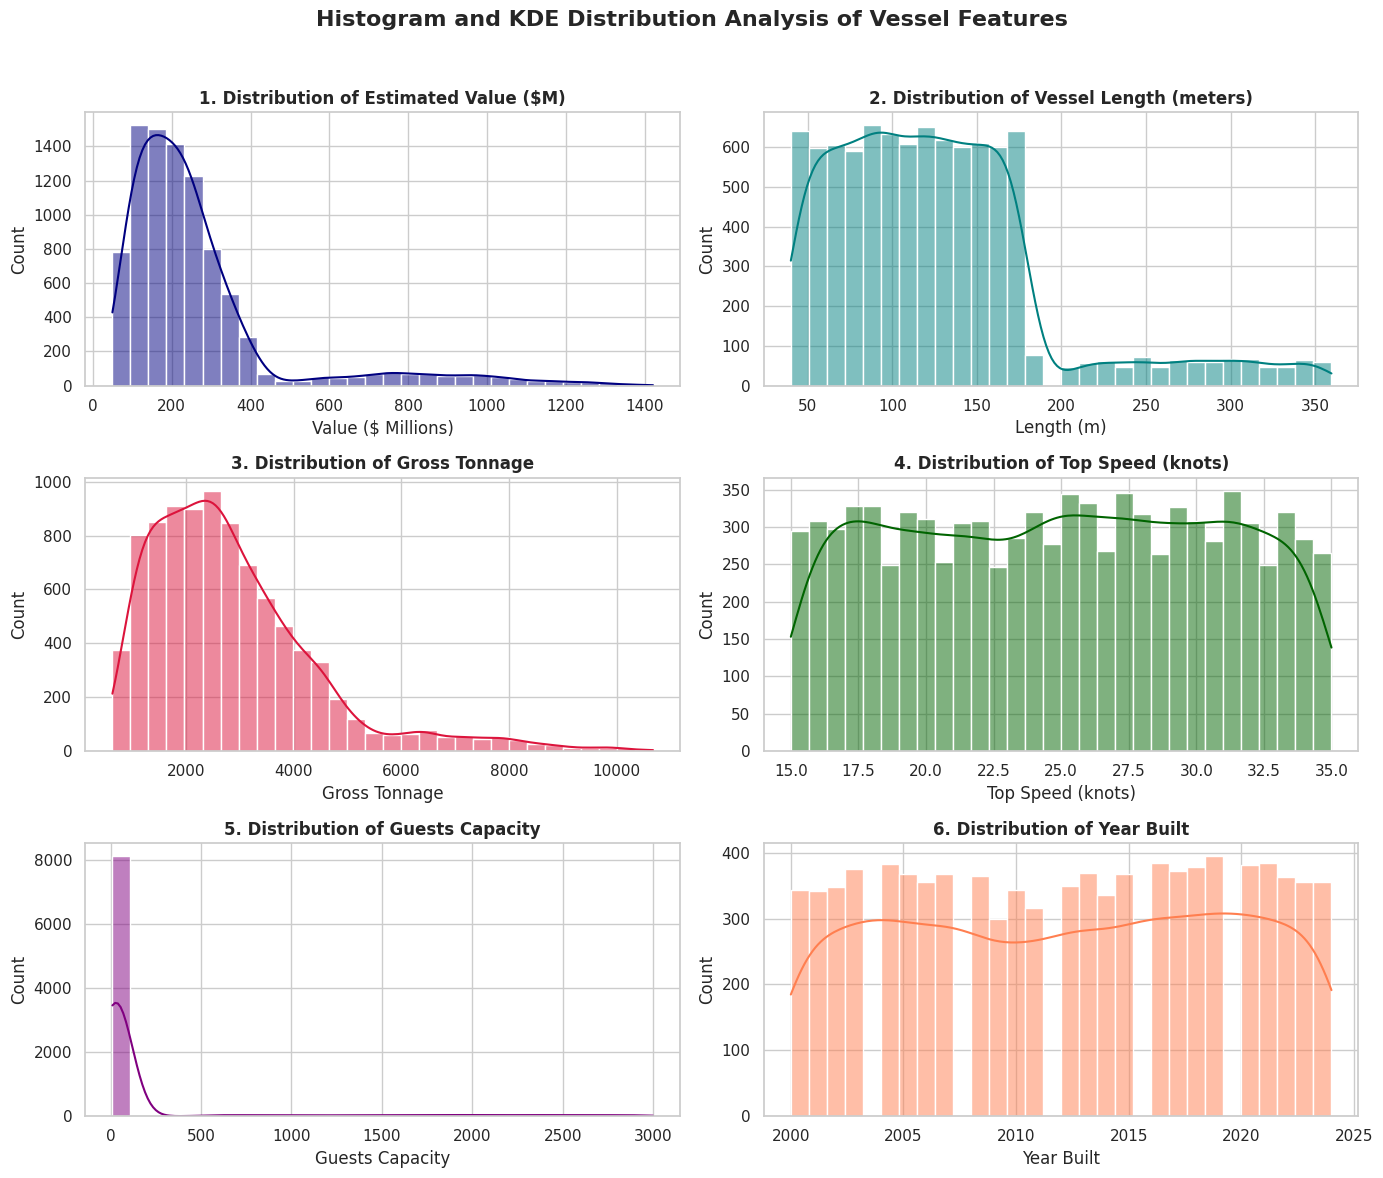


DESCRIPTION OF HISTOGRAMS:
--------------------------------------------------------------------------------
1. Estimated Value ($M): Shows valuation density; multi-modal behavior reflects differences between superyachts and large cruises.
2. Vessel Length: Examines size frequency; highlights distinct operational size tiers.
3. Gross Tonnage: Measures volume distribution; showcases high skewness due to massive cruise ships.
4. Top Speed: Displays speed distribution across fleet; peaks indicate standard propulsion limits.
5. Guests Capacity: Highlights differences between private superyachts and high-capacity cruise vessels.
6. Year Built: Evaluates fleet age distribution across manufacturing decades.
--------------------------------------------------------------------------------



In [5]:
# ==============================================================================
# HISTOGRAMS
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Set style for seaborn
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
fig.suptitle("Histogram and KDE Distribution Analysis of Vessel Features", fontsize=16, fontweight='bold')

# Plot 1: Estimated Value Distribution
sns.histplot(df['Estimated_Value_USD_Millions'], kde=True, ax=axes[0, 0], color='navy', bins=30)
axes[0, 0].set_title("1. Distribution of Estimated Value ($M)", fontweight='bold')
axes[0, 0].set_xlabel("Value ($ Millions)")

# Plot 2: Length (meters) Distribution
sns.histplot(df['Length_meters'], kde=True, ax=axes[0, 1], color='teal', bins=30)
axes[0, 1].set_title("2. Distribution of Vessel Length (meters)", fontweight='bold')
axes[0, 1].set_xlabel("Length (m)")

# Plot 3: Gross Tonnage Distribution
sns.histplot(df['Gross_Tonnage'], kde=True, ax=axes[1, 0], color='crimson', bins=30)
axes[1, 0].set_title("3. Distribution of Gross Tonnage", fontweight='bold')
axes[1, 0].set_xlabel("Gross Tonnage")

# Plot 4: Top Speed Distribution
sns.histplot(df['Top_Speed_knots'], kde=True, ax=axes[1, 1], color='darkgreen', bins=30)
axes[1, 1].set_title("4. Distribution of Top Speed (knots)", fontweight='bold')
axes[1, 1].set_xlabel("Top Speed (knots)")

# Plot 5: Guests Capacity Distribution
sns.histplot(df['Guests_Capacity'], kde=True, ax=axes[2, 0], color='purple', bins=30)
axes[2, 0].set_title("5. Distribution of Guests Capacity", fontweight='bold')
axes[2, 0].set_xlabel("Guests Capacity")

# Plot 6: Year Built Distribution
sns.histplot(df['Year_Built'], kde=True, ax=axes[2, 1], color='coral', bins=30)
axes[2, 1].set_title("6. Distribution of Year Built", fontweight='bold')
axes[2, 1].set_xlabel("Year Built")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("""
DESCRIPTION OF HISTOGRAMS:
--------------------------------------------------------------------------------
1. Estimated Value ($M): Shows valuation density; multi-modal behavior reflects differences between superyachts and large cruises.
2. Vessel Length: Examines size frequency; highlights distinct operational size tiers.
3. Gross Tonnage: Measures volume distribution; showcases high skewness due to massive cruise ships.
4. Top Speed: Displays speed distribution across fleet; peaks indicate standard propulsion limits.
5. Guests Capacity: Highlights differences between private superyachts and high-capacity cruise vessels.
6. Year Built: Evaluates fleet age distribution across manufacturing decades.
--------------------------------------------------------------------------------
""")

/tmp/ipykernel_604/570239134.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(data=df, x='Year_Built', y='Top_Speed_knots', hue='Type', ax=axes[1, 1], ci=None)


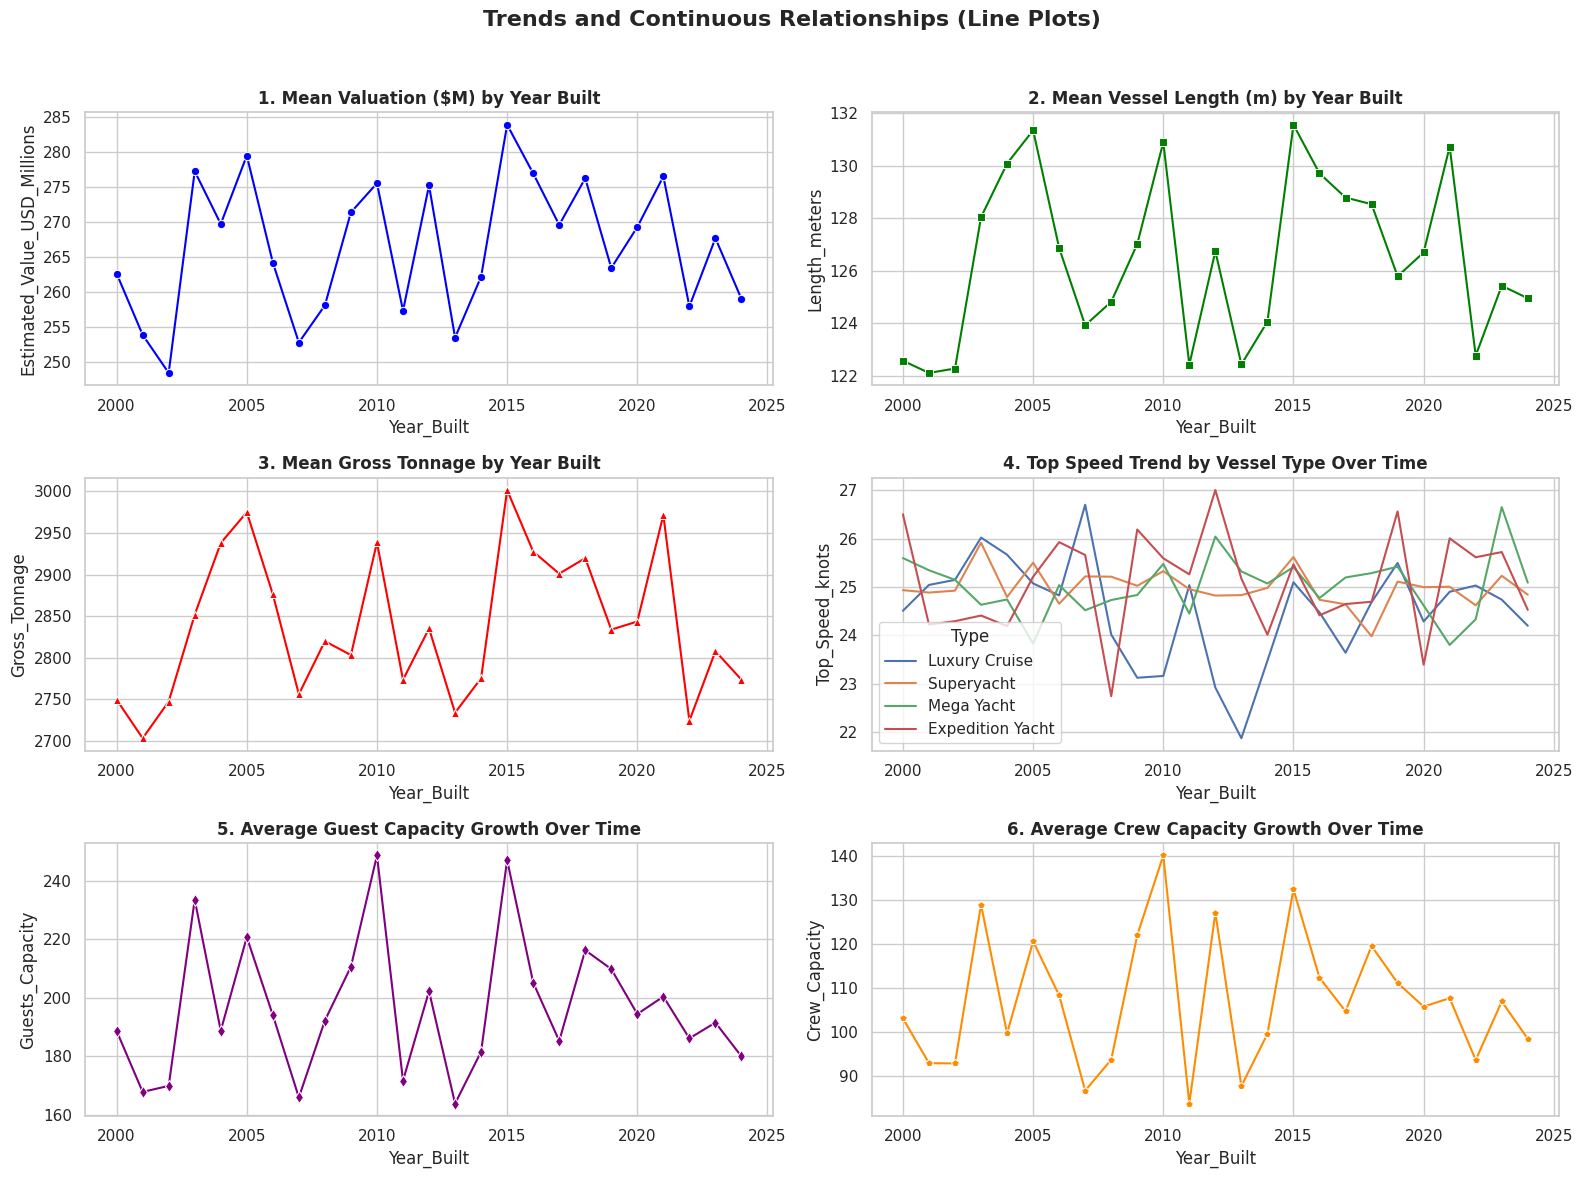


DESCRIPTION OF LINE PLOTS:
--------------------------------------------------------------------------------
1. Valuation Trend: Tracks average asset values over time to detect market valuation growth.
2. Length Trend: Tracks structural evolution in average vessel lengths built each year.
3. Tonnage Trend: Illustrates growth in vessel volume and displacement across build years.
4. Speed Trend by Type: Highlights performance speed variations over time across distinct vessel categories.
5. Guest Capacity Trend: Examines changes in average passenger hosting capacity over manufacturing eras.
6. Crew Capacity Trend: Shows scaling in staffing needs relative to modern ship construction trends.
--------------------------------------------------------------------------------



In [6]:
# ==============================================================================
# LINEPLOTS
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 2, figsize=(16, 12))
fig.suptitle("Trends and Continuous Relationships (Line Plots)", fontsize=16, fontweight='bold')

# Group data by year for trend analysis
yearly_trend = df.groupby('Year_Built').agg({
    'Estimated_Value_USD_Millions': 'mean',
    'Length_meters': 'mean',
    'Gross_Tonnage': 'mean',
    'Top_Speed_knots': 'mean',
    'Guests_Capacity': 'mean',
    'Crew_Capacity': 'mean'
}).reset_index()

# Plot 1: Average Value over Years
sns.lineplot(data=yearly_trend, x='Year_Built', y='Estimated_Value_USD_Millions', ax=axes[0, 0], marker='o', color='blue')
axes[0, 0].set_title("1. Mean Valuation ($M) by Year Built", fontweight='bold')

# Plot 2: Average Length over Years
sns.lineplot(data=yearly_trend, x='Year_Built', y='Length_meters', ax=axes[0, 1], marker='s', color='green')
axes[0, 1].set_title("2. Mean Vessel Length (m) by Year Built", fontweight='bold')

# Plot 3: Average Gross Tonnage over Years
sns.lineplot(data=yearly_trend, x='Year_Built', y='Gross_Tonnage', ax=axes[1, 0], marker='^', color='red')
axes[1, 0].set_title("3. Mean Gross Tonnage by Year Built", fontweight='bold')

# Plot 4: Top Speed vs Year Built by Vessel Type
sns.lineplot(data=df, x='Year_Built', y='Top_Speed_knots', hue='Type', ax=axes[1, 1], ci=None)
axes[1, 1].set_title("4. Top Speed Trend by Vessel Type Over Time", fontweight='bold')

# Plot 5: Guests Capacity Trend Over Time
sns.lineplot(data=yearly_trend, x='Year_Built', y='Guests_Capacity', ax=axes[2, 0], marker='d', color='purple')
axes[2, 0].set_title("5. Average Guest Capacity Growth Over Time", fontweight='bold')

# Plot 6: Crew Capacity Trend Over Time
sns.lineplot(data=yearly_trend, x='Year_Built', y='Crew_Capacity', ax=axes[2, 1], marker='p', color='darkorange')
axes[2, 1].set_title("6. Average Crew Capacity Growth Over Time", fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("""
DESCRIPTION OF LINE PLOTS:
--------------------------------------------------------------------------------
1. Valuation Trend: Tracks average asset values over time to detect market valuation growth.
2. Length Trend: Tracks structural evolution in average vessel lengths built each year.
3. Tonnage Trend: Illustrates growth in vessel volume and displacement across build years.
4. Speed Trend by Type: Highlights performance speed variations over time across distinct vessel categories.
5. Guest Capacity Trend: Examines changes in average passenger hosting capacity over manufacturing eras.
6. Crew Capacity Trend: Shows scaling in staffing needs relative to modern ship construction trends.
--------------------------------------------------------------------------------
""")

/tmp/ipykernel_604/3169388999.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Type', ax=axes[0, 0], palette='Blues_d')
/tmp/ipykernel_604/3169388999.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='Current_Region', ax=axes[0, 1], palette='Greens_d', order=df['Current_Region'].value_counts().index)
/tmp/ipykernel_604/3169388999.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df[df['Builder'].isin(top_builders)], y='Builder', ax=axes[1, 0], palette='Reds_d', order=top_builders)
/tmp/ipykernel_60

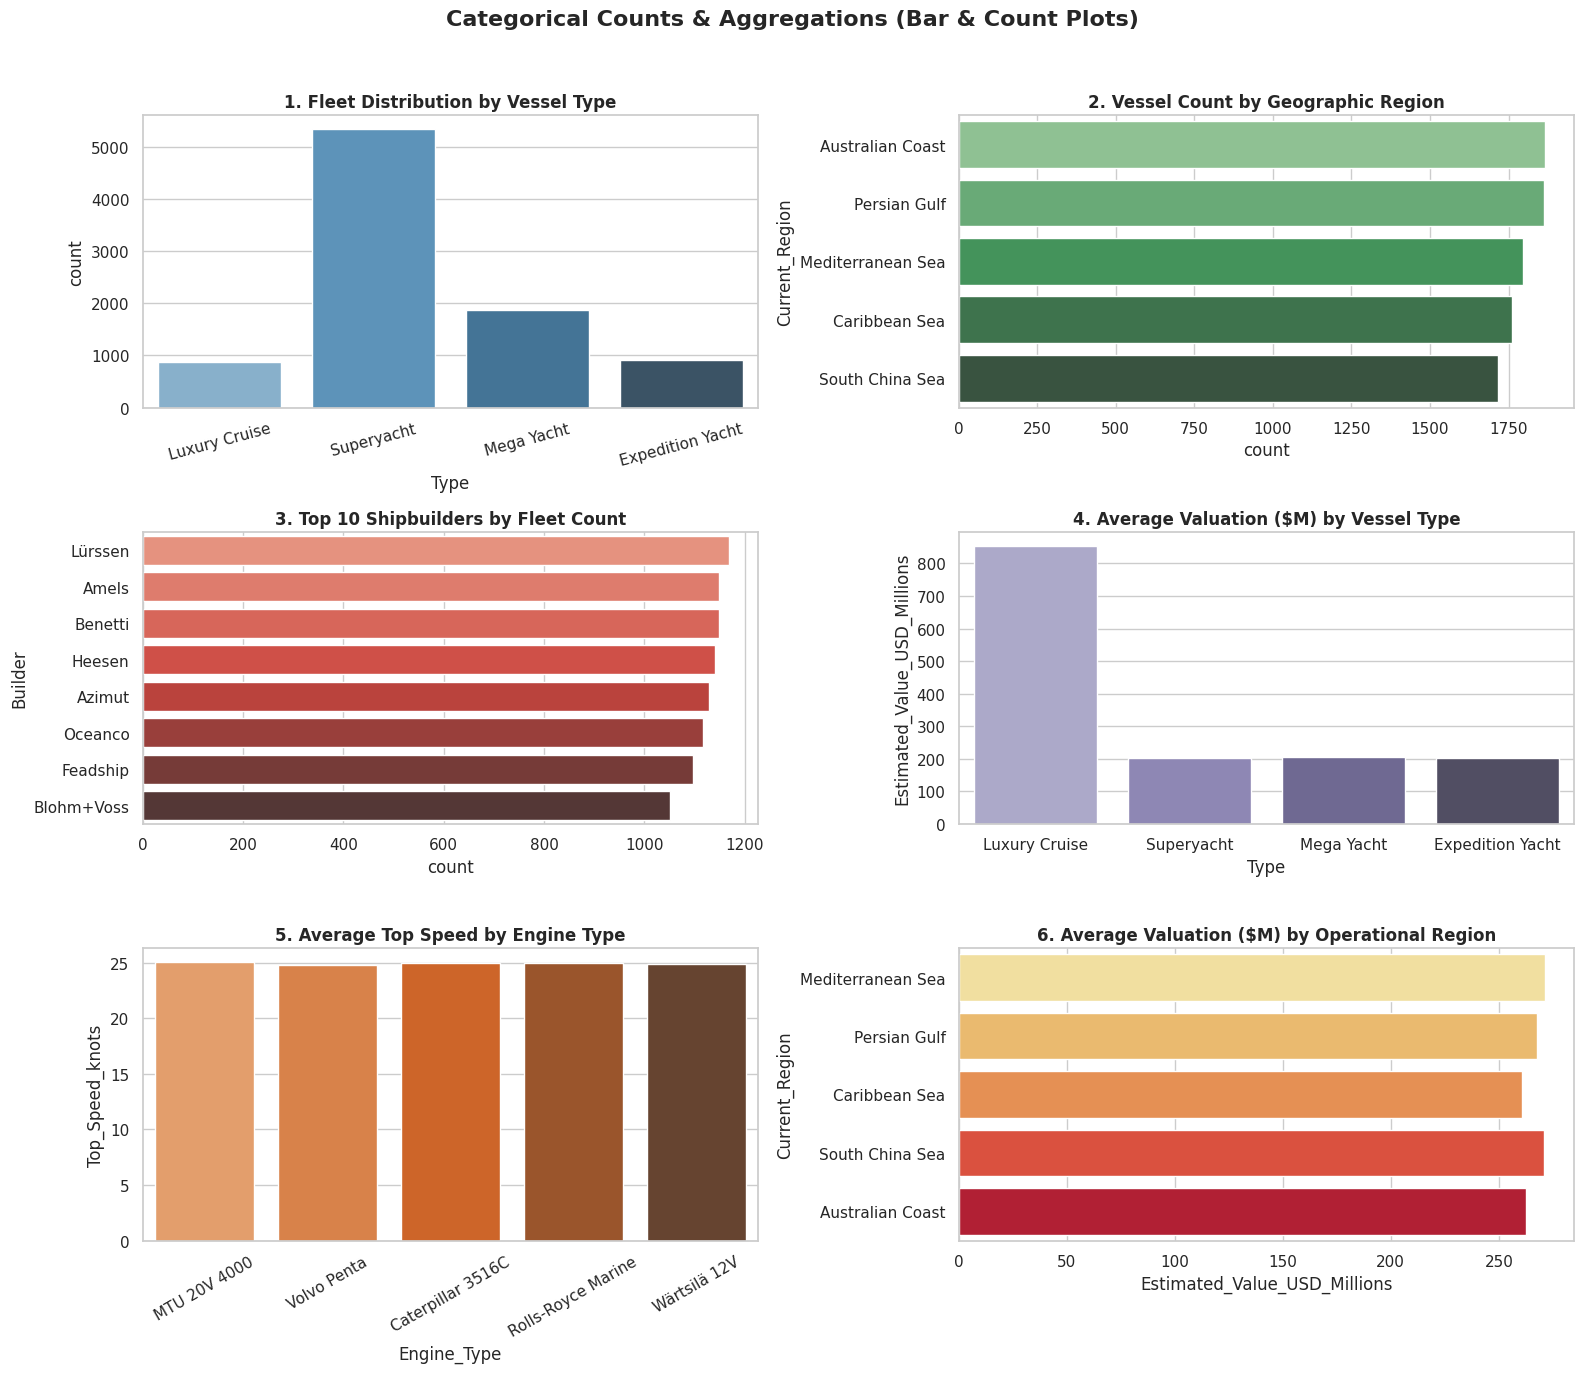


DESCRIPTION OF BAR & COUNT PLOTS:
--------------------------------------------------------------------------------
1. Fleet Distribution by Type: Visualizes absolute counts of Superyachts vs Cruises.
2. Regional Count: Highlights geographic operational hotspots across oceans and seas.
3. Top 10 Builders: Identifies leading shipbuilders dominating overall vessel volume.
4. Mean Value by Type: Compares capital investment scale across vessel categories.
5. Speed by Engine: Compares efficiency and power output across different engine configurations.
6. Mean Value by Region: Evaluates high-value asset concentration in global regions.
--------------------------------------------------------------------------------



In [7]:
# ==============================================================================
# SECTION 5: BAR PLOTS AND COUNT PLOTS
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 2, figsize=(16, 14))
fig.suptitle("Categorical Counts & Aggregations (Bar & Count Plots)", fontsize=16, fontweight='bold')

# Plot 1: Count of Vessel Types
sns.countplot(data=df, x='Type', ax=axes[0, 0], palette='Blues_d')
axes[0, 0].set_title("1. Fleet Distribution by Vessel Type", fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=15)

# Plot 2: Count by Current Region
sns.countplot(data=df, y='Current_Region', ax=axes[0, 1], palette='Greens_d', order=df['Current_Region'].value_counts().index)
axes[0, 1].set_title("2. Vessel Count by Geographic Region", fontweight='bold')

# Plot 3: Top 10 Ship Builders Count
top_builders = df['Builder'].value_counts().nlargest(10).index
sns.countplot(data=df[df['Builder'].isin(top_builders)], y='Builder', ax=axes[1, 0], palette='Reds_d', order=top_builders)
axes[1, 0].set_title("3. Top 10 Shipbuilders by Fleet Count", fontweight='bold')

# Plot 4: Mean Value by Vessel Type
sns.barplot(data=df, x='Type', y='Estimated_Value_USD_Millions', ax=axes[1, 1], palette='Purples_d', ci=None)
axes[1, 1].set_title("4. Average Valuation ($M) by Vessel Type", fontweight='bold')

# Plot 5: Mean Top Speed by Engine Type
sns.barplot(data=df, x='Engine_Type', y='Top_Speed_knots', ax=axes[2, 0], palette='Oranges_d', ci=None)
axes[2, 0].set_title("5. Average Top Speed by Engine Type", fontweight='bold')
axes[2, 0].tick_params(axis='x', rotation=30)

# Plot 6: Average Value by Region
sns.barplot(data=df, x='Estimated_Value_USD_Millions', y='Current_Region', ax=axes[2, 1], palette='YlOrRd', ci=None)
axes[2, 1].set_title("6. Average Valuation ($M) by Operational Region", fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("""
DESCRIPTION OF BAR & COUNT PLOTS:
--------------------------------------------------------------------------------
1. Fleet Distribution by Type: Visualizes absolute counts of Superyachts vs Cruises.
2. Regional Count: Highlights geographic operational hotspots across oceans and seas.
3. Top 10 Builders: Identifies leading shipbuilders dominating overall vessel volume.
4. Mean Value by Type: Compares capital investment scale across vessel categories.
5. Speed by Engine: Compares efficiency and power output across different engine configurations.
6. Mean Value by Region: Evaluates high-value asset concentration in global regions.
--------------------------------------------------------------------------------
""")

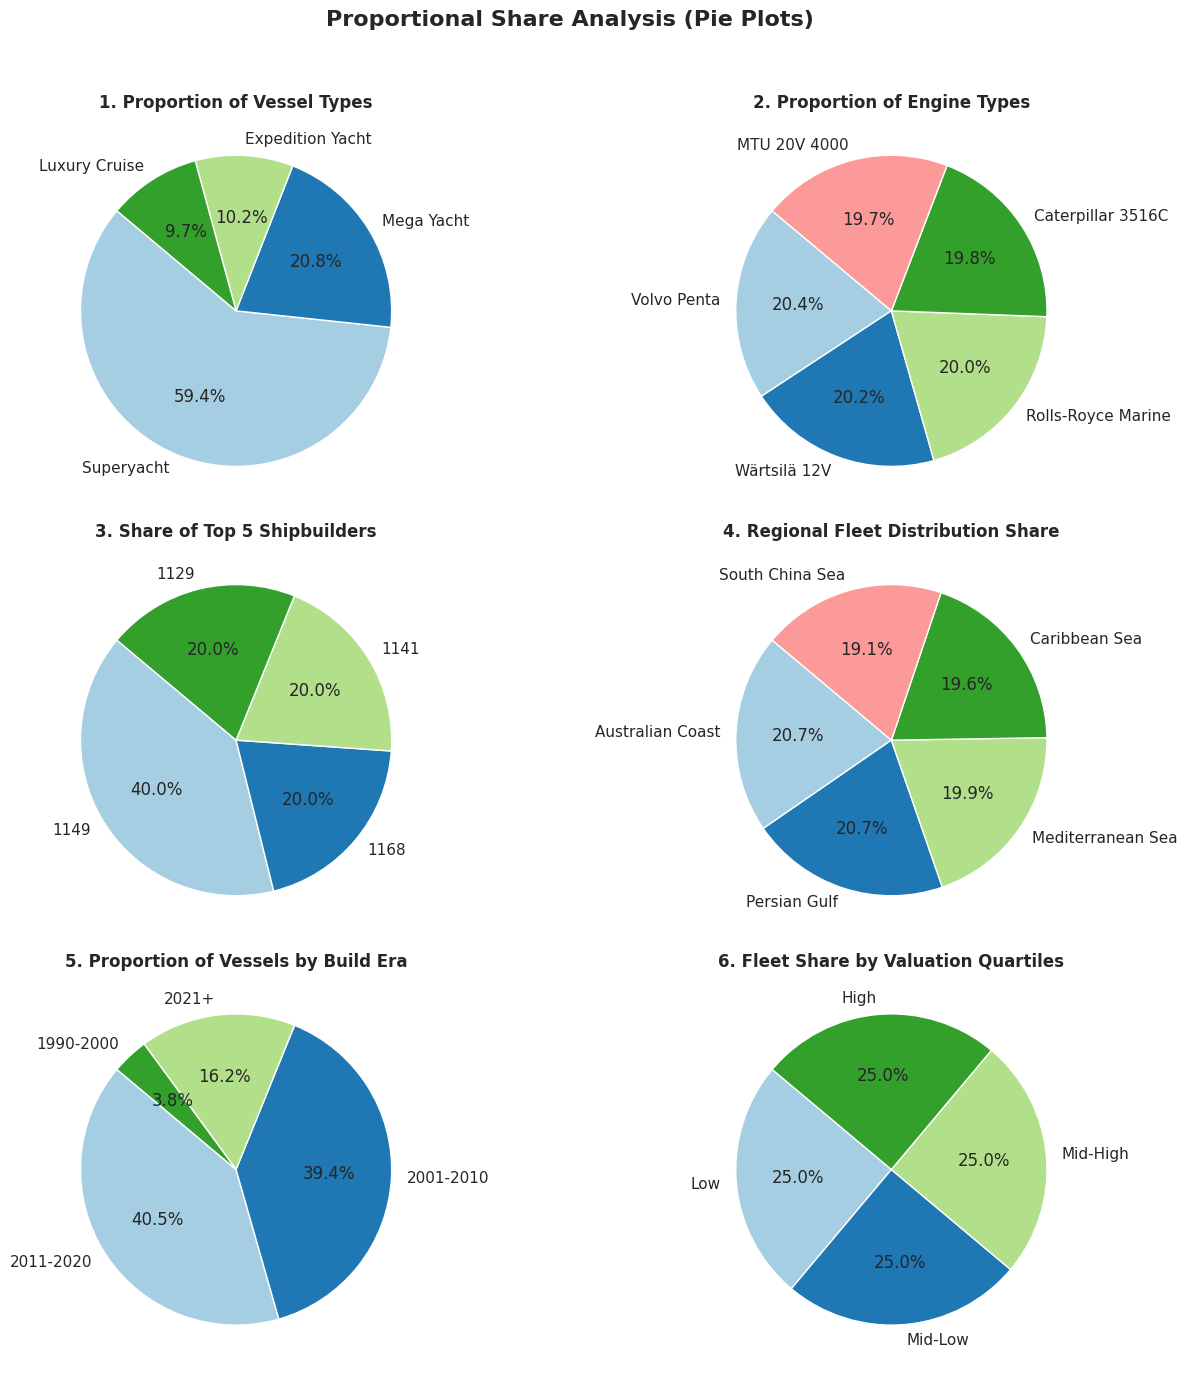


DESCRIPTION OF PIE PLOTS:
--------------------------------------------------------------------------------
1. Vessel Types Share: Visualizes percentage composition of superyachts vs cruises in fleet.
2. Engine Types Share: Highlights dominant propulsion technologies across the dataset.
3. Top 5 Builders Share: Displays market concentration among top shipbuilders.
4. Regional Share: Shows market share breakdown across global operational regions.
5. Era Built Share: Demonstrates fleet age structure partitioned into distinct build decades.
6. Valuation Quartiles: Divides fleet into balanced 25% financial tiers for segmentation.
--------------------------------------------------------------------------------



In [8]:
# ==============================================================================
# PIEPLOTS
# ==============================================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
fig.suptitle("Proportional Share Analysis (Pie Plots)", fontsize=16, fontweight='bold')

# Helper function to plot pie chart
def draw_pie(ax, series, title):
    values = series.value_counts()
    ax.pie(values, labels=values.index, autopct='%1.1f%%', startangle=140, colors=plt.cm.Paired.colors)
    ax.set_title(title, fontweight='bold')

# Plot 1: Share of Vessel Types
draw_pie(axes[0, 0], df['Type'], "1. Proportion of Vessel Types")

# Plot 2: Share of Engine Types
draw_pie(axes[0, 1], df['Engine_Type'], "2. Proportion of Engine Types")

# Plot 3: Top 5 Builders Share
top_5_builders = df['Builder'].value_counts().nlargest(5)
draw_pie(axes[1, 0], pd.Series(top_5_builders), "3. Share of Top 5 Shipbuilders")

# Plot 4: Operational Region Share
draw_pie(axes[1, 1], df['Current_Region'], "4. Regional Fleet Distribution Share")

# Plot 5: Era Built Share
era_series = pd.cut(df['Year_Built'], bins=[1990, 2000, 2010, 2020, 2030], labels=['1990-2000', '2001-2010', '2011-2020', '2021+'])
draw_pie(axes[2, 0], era_series, "5. Proportion of Vessels by Build Era")

# Plot 6: Valuation Class Share
val_class = pd.qcut(df['Estimated_Value_USD_Millions'], q=4, labels=['Low', 'Mid-Low', 'Mid-High', 'High'])
draw_pie(axes[2, 1], val_class, "6. Fleet Share by Valuation Quartiles")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("""
DESCRIPTION OF PIE PLOTS:
--------------------------------------------------------------------------------
1. Vessel Types Share: Visualizes percentage composition of superyachts vs cruises in fleet.
2. Engine Types Share: Highlights dominant propulsion technologies across the dataset.
3. Top 5 Builders Share: Displays market concentration among top shipbuilders.
4. Regional Share: Shows market share breakdown across global operational regions.
5. Era Built Share: Demonstrates fleet age structure partitioned into distinct build decades.
6. Valuation Quartiles: Divides fleet into balanced 25% financial tiers for segmentation.
--------------------------------------------------------------------------------
""")

/tmp/ipykernel_604/2181413365.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Type', y='Estimated_Value_USD_Millions', ax=axes[0, 0], palette='Set2')
/tmp/ipykernel_604/2181413365.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Type', y='Length_meters', ax=axes[0, 1], palette='Set2')
/tmp/ipykernel_604/2181413365.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Engine_Type', y='Top_Speed_knots', ax=axes[1, 0], palette='Set3')
/tmp/ipykernel_604/2181413365.py:25: FutureWarning: 

Passing `pale

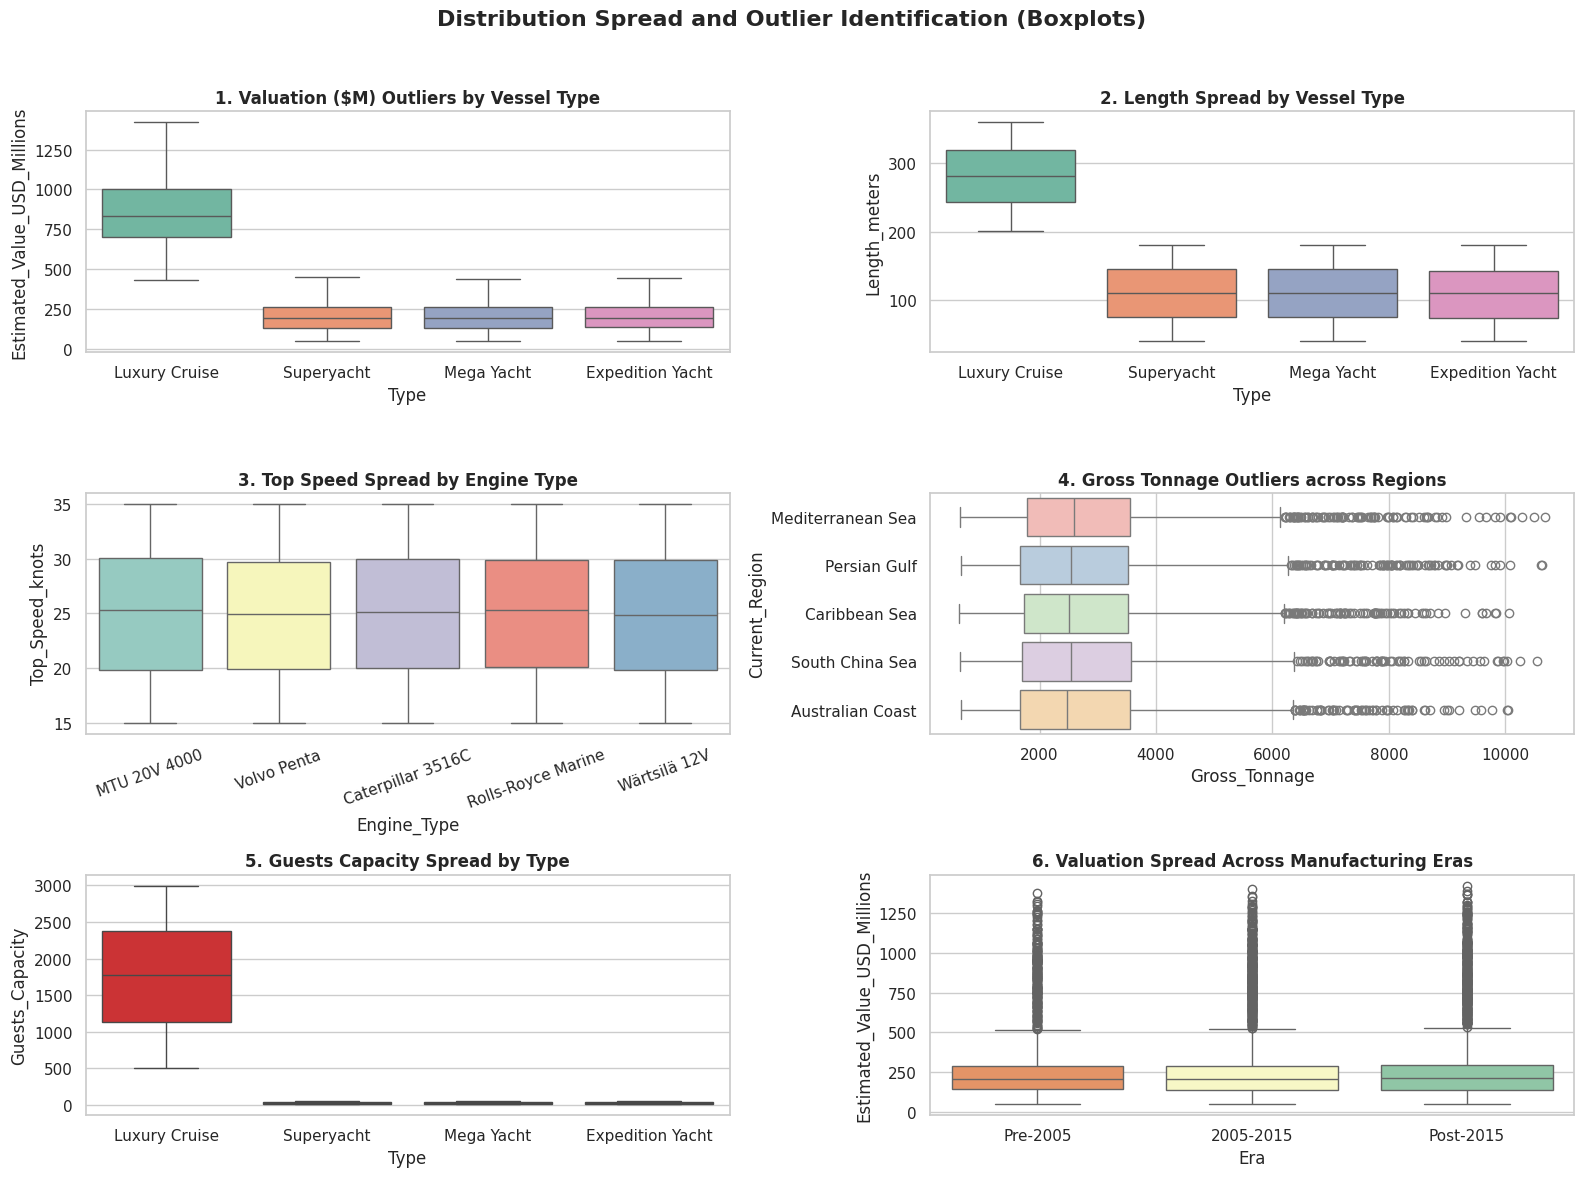


DESCRIPTION OF BOXPLOTS:
--------------------------------------------------------------------------------
1. Valuation Outliers: Detects pricing anomalies and extreme values across superyachts and cruises.
2. Length Spread: Identifies median lengths and upper/lower bounds per vessel category.
3. Engine Speed Ranges: Compares variance and speed ceilings across engine variants.
4. Tonnage Dispersion: Shows volume concentration and extreme ship sizes per region.
5. Guests Capacity Spread: Highlights variance in passenger accommodations per category.
6. Era Valuation Comparison: Shows financial dispersion and median valuation changes across eras.
--------------------------------------------------------------------------------



In [9]:
# ==============================================================================
# BOXPLOTS
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 2, figsize=(16, 12))
fig.suptitle("Distribution Spread and Outlier Identification (Boxplots)", fontsize=16, fontweight='bold')

# Plot 1: Value by Vessel Type
sns.boxplot(data=df, x='Type', y='Estimated_Value_USD_Millions', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title("1. Valuation ($M) Outliers by Vessel Type", fontweight='bold')

# Plot 2: Length by Vessel Type
sns.boxplot(data=df, x='Type', y='Length_meters', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title("2. Length Spread by Vessel Type", fontweight='bold')

# Plot 3: Top Speed by Engine Type
sns.boxplot(data=df, x='Engine_Type', y='Top_Speed_knots', ax=axes[1, 0], palette='Set3')
axes[1, 0].set_title("3. Top Speed Spread by Engine Type", fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=20)

# Plot 4: Gross Tonnage by Region
sns.boxplot(data=df, x='Gross_Tonnage', y='Current_Region', ax=axes[1, 1], palette='Pastel1')
axes[1, 1].set_title("4. Gross Tonnage Outliers across Regions", fontweight='bold')

# Plot 5: Guests Capacity by Vessel Type
sns.boxplot(data=df, x='Type', y='Guests_Capacity', ax=axes[2, 0], palette='Set1')
axes[2, 0].set_title("5. Guests Capacity Spread by Type", fontweight='bold')

# Plot 6: Valuation Spread across Build Eras
df['Era'] = pd.cut(df['Year_Built'], bins=[1990, 2005, 2015, 2026], labels=['Pre-2005', '2005-2015', 'Post-2015'])
sns.boxplot(data=df, x='Era', y='Estimated_Value_USD_Millions', ax=axes[2, 1], palette='Spectral')
axes[2, 1].set_title("6. Valuation Spread Across Manufacturing Eras", fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("""
DESCRIPTION OF BOXPLOTS:
--------------------------------------------------------------------------------
1. Valuation Outliers: Detects pricing anomalies and extreme values across superyachts and cruises.
2. Length Spread: Identifies median lengths and upper/lower bounds per vessel category.
3. Engine Speed Ranges: Compares variance and speed ceilings across engine variants.
4. Tonnage Dispersion: Shows volume concentration and extreme ship sizes per region.
5. Guests Capacity Spread: Highlights variance in passenger accommodations per category.
6. Era Valuation Comparison: Shows financial dispersion and median valuation changes across eras.
--------------------------------------------------------------------------------
""")

/tmp/ipykernel_604/1655629293.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='Type', y='Estimated_Value_USD_Millions', ax=axes[0, 0], palette='muted', inner='quartile')
/tmp/ipykernel_604/1655629293.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='Engine_Type', y='Top_Speed_knots', ax=axes[0, 1], palette='muted', inner='box')
/tmp/ipykernel_604/1655629293.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='Type', y='Length_meters', ax=axes[1, 0], palette='dark', inner='point')
/tmp/ipyke

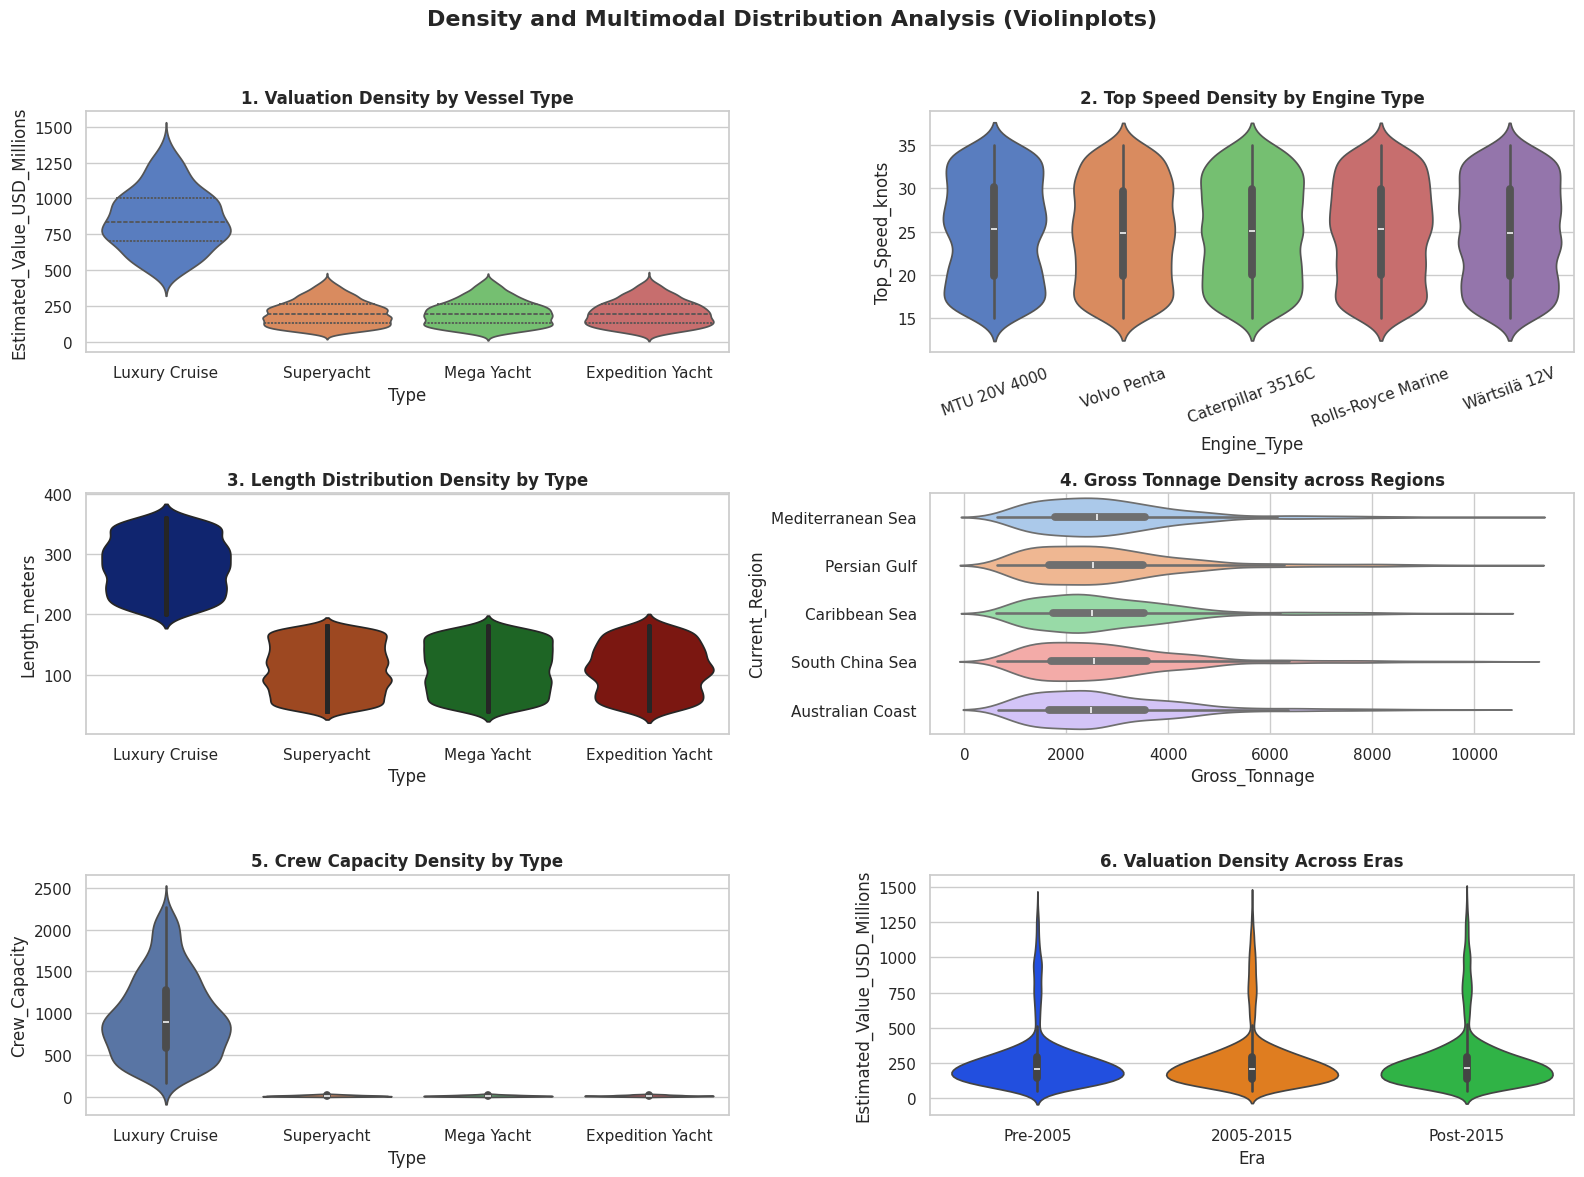


DESCRIPTION OF VIOLINPLOTS:
--------------------------------------------------------------------------------
1. Valuation Density: Reveals multimodal density distribution peaks in valuation across vessel types.
2. Speed Density by Engine: Displays probability density of top speeds achievable per engine class.
3. Length Density: Visualizes structural length concentrations across superyachts vs cruises.
4. Tonnage Density per Region: Demonstrates regional distributions of light vs massive ships.
5. Crew Density: Shows staffing requirement distributions across vessel categories.
6. Era Density: Compares valuation probability mass across historical construction eras.
--------------------------------------------------------------------------------



In [10]:
# ==============================================================================
# VIOLINPLOTS
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 2, figsize=(16, 12))
fig.suptitle("Density and Multimodal Distribution Analysis (Violinplots)", fontsize=16, fontweight='bold')

# Plot 1: Estimated Value Density by Vessel Type
sns.violinplot(data=df, x='Type', y='Estimated_Value_USD_Millions', ax=axes[0, 0], palette='muted', inner='quartile')
axes[0, 0].set_title("1. Valuation Density by Vessel Type", fontweight='bold')

# Plot 2: Top Speed Density by Engine Type
sns.violinplot(data=df, x='Engine_Type', y='Top_Speed_knots', ax=axes[0, 1], palette='muted', inner='box')
axes[0, 1].set_title("2. Top Speed Density by Engine Type", fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=20)

# Plot 3: Length Density by Vessel Type
sns.violinplot(data=df, x='Type', y='Length_meters', ax=axes[1, 0], palette='dark', inner='point')
axes[1, 0].set_title("3. Length Distribution Density by Type", fontweight='bold')

# Plot 4: Gross Tonnage Density by Region
sns.violinplot(data=df, y='Current_Region', x='Gross_Tonnage', ax=axes[1, 1], palette='pastel')
axes[1, 1].set_title("4. Gross Tonnage Density across Regions", fontweight='bold')

# Plot 5: Crew Capacity Density by Vessel Type
sns.violinplot(data=df, x='Type', y='Crew_Capacity', ax=axes[2, 0], palette='deep')
axes[2, 0].set_title("5. Crew Capacity Density by Type", fontweight='bold')

# Plot 6: Valuation Density by Build Era
sns.violinplot(data=df, x='Era', y='Estimated_Value_USD_Millions', ax=axes[2, 1], palette='bright')
axes[2, 1].set_title("6. Valuation Density Across Eras", fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("""
DESCRIPTION OF VIOLINPLOTS:
--------------------------------------------------------------------------------
1. Valuation Density: Reveals multimodal density distribution peaks in valuation across vessel types.
2. Speed Density by Engine: Displays probability density of top speeds achievable per engine class.
3. Length Density: Visualizes structural length concentrations across superyachts vs cruises.
4. Tonnage Density per Region: Demonstrates regional distributions of light vs massive ships.
5. Crew Density: Shows staffing requirement distributions across vessel categories.
6. Era Density: Compares valuation probability mass across historical construction eras.
--------------------------------------------------------------------------------
""")

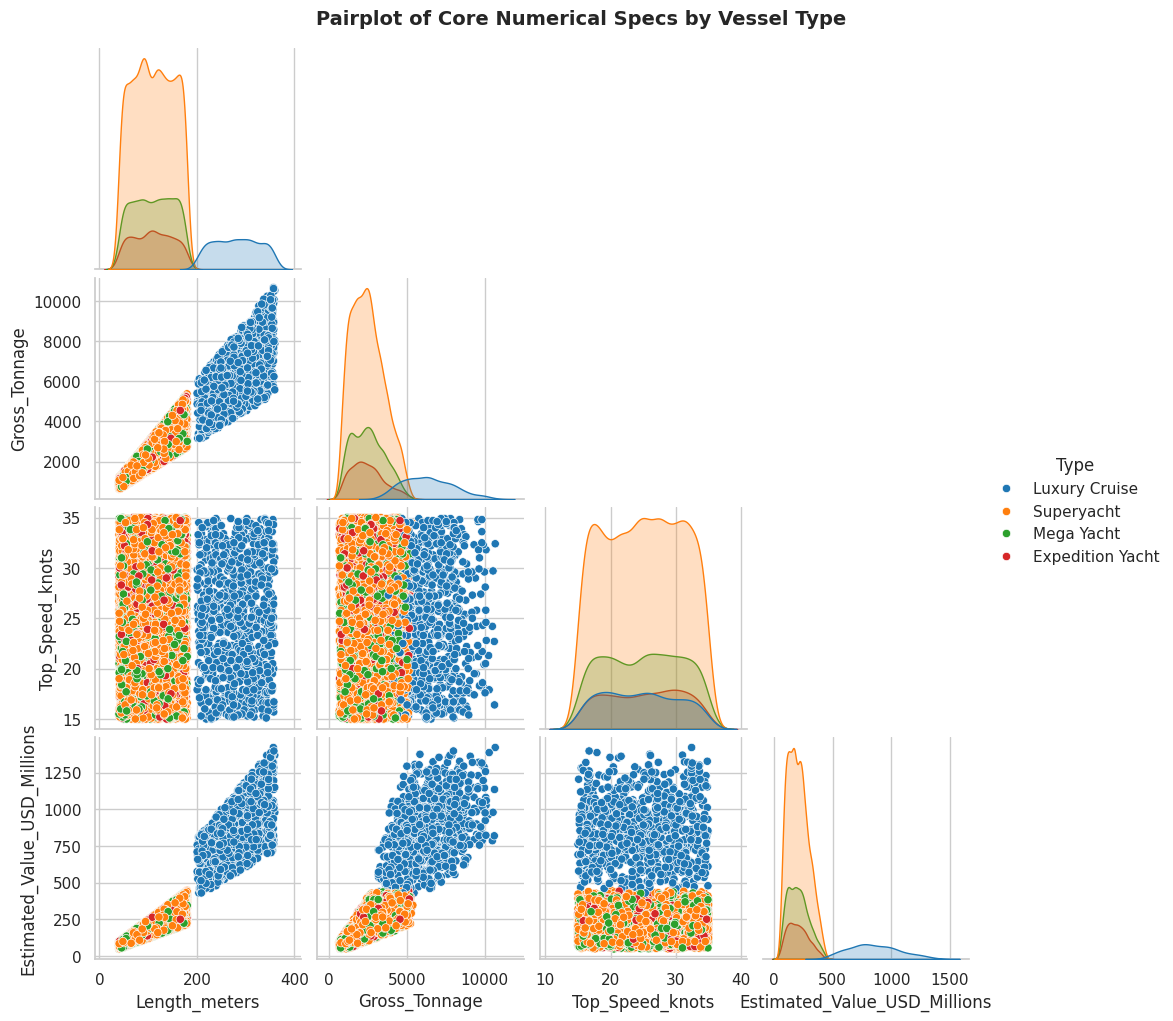

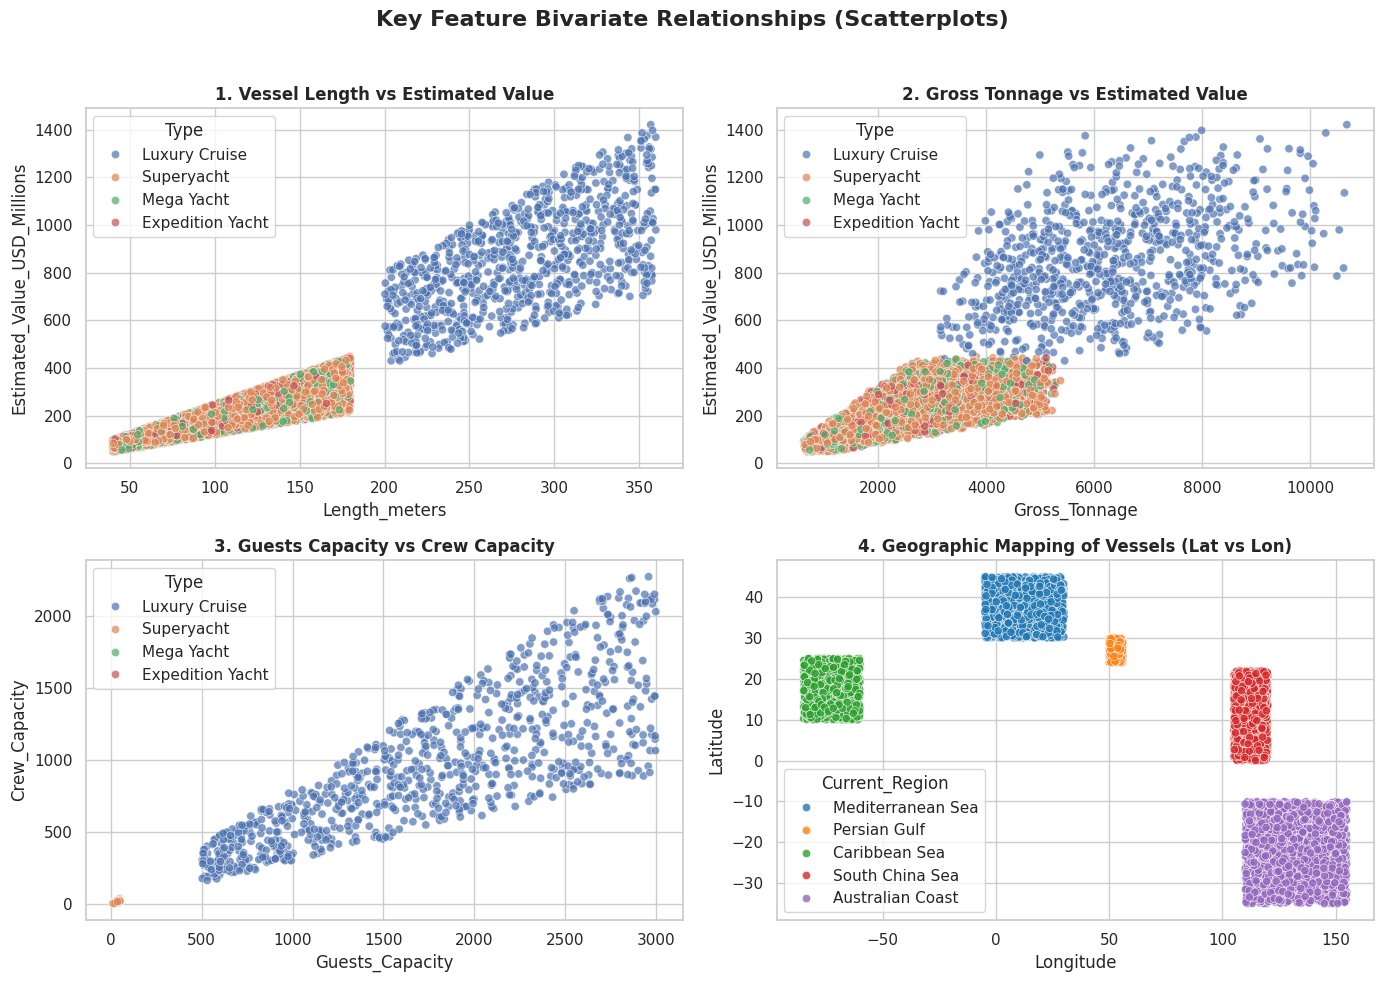


DESCRIPTION OF PAIRPLOT & SCATTERPLOTS:
--------------------------------------------------------------------------------
1. Pairplot: Evaluates multi-dimensional feature scatter matrices with target hue segmentation.
2. Length vs Value: Demonstrates non-linear scaling between physical vessel length and monetary valuation.
3. Tonnage vs Value: Shows strong positive correlation between volumetric tonnage and asset price.
4. Guests vs Crew: Illustrates proportional staffing dynamics relative to guest accommodation limits.
5. Geo-Coordinates (Lat/Lon): Plots spatial distribution of vessels on global geographic grid.
--------------------------------------------------------------------------------



In [11]:
# ==============================================================================
# PAIRPLOT & SCATTERPLOTS
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Part A: Pairplot using 'Type' as target hue
selected_features = ['Length_meters', 'Gross_Tonnage', 'Top_Speed_knots', 'Estimated_Value_USD_Millions', 'Type']
pair_grid = sns.pairplot(df[selected_features], hue='Type', palette='tab10', corner=True)
pair_grid.fig.suptitle("Pairplot of Core Numerical Specs by Vessel Type", y=1.02, fontsize=14, fontweight='bold')
plt.show()

# Part B: Important Scatterplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Key Feature Bivariate Relationships (Scatterplots)", fontsize=16, fontweight='bold')

# Scatter 1: Length vs Value
sns.scatterplot(data=df, x='Length_meters', y='Estimated_Value_USD_Millions', hue='Type', ax=axes[0, 0], alpha=0.7)
axes[0, 0].set_title("1. Vessel Length vs Estimated Value", fontweight='bold')

# Scatter 2: Gross Tonnage vs Value
sns.scatterplot(data=df, x='Gross_Tonnage', y='Estimated_Value_USD_Millions', hue='Type', ax=axes[0, 1], alpha=0.7)
axes[0, 1].set_title("2. Gross Tonnage vs Estimated Value", fontweight='bold')

# Scatter 3: Guests vs Crew Capacity
sns.scatterplot(data=df, x='Guests_Capacity', y='Crew_Capacity', hue='Type', ax=axes[1, 0], alpha=0.7)
axes[1, 0].set_title("3. Guests Capacity vs Crew Capacity", fontweight='bold')

# Scatter 4: Latitude vs Longitude (Geographic Coordinates)
sns.scatterplot(data=df, x='Longitude', y='Latitude', hue='Current_Region', ax=axes[1, 1], palette='tab10', alpha=0.8)
axes[1, 1].set_title("4. Geographic Mapping of Vessels (Lat vs Lon)", fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("""
DESCRIPTION OF PAIRPLOT & SCATTERPLOTS:
--------------------------------------------------------------------------------
1. Pairplot: Evaluates multi-dimensional feature scatter matrices with target hue segmentation.
2. Length vs Value: Demonstrates non-linear scaling between physical vessel length and monetary valuation.
3. Tonnage vs Value: Shows strong positive correlation between volumetric tonnage and asset price.
4. Guests vs Crew: Illustrates proportional staffing dynamics relative to guest accommodation limits.
5. Geo-Coordinates (Lat/Lon): Plots spatial distribution of vessels on global geographic grid.
--------------------------------------------------------------------------------
""")

/tmp/ipykernel_604/614700879.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_fe, x='Type', y='Value_Per_Meter', ax=axes[2, 0], palette='magma')
/tmp/ipykernel_604/614700879.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_fe, x='Value_Per_Tonnage', y='Current_Region', ax=axes[2, 1], palette='viridis')


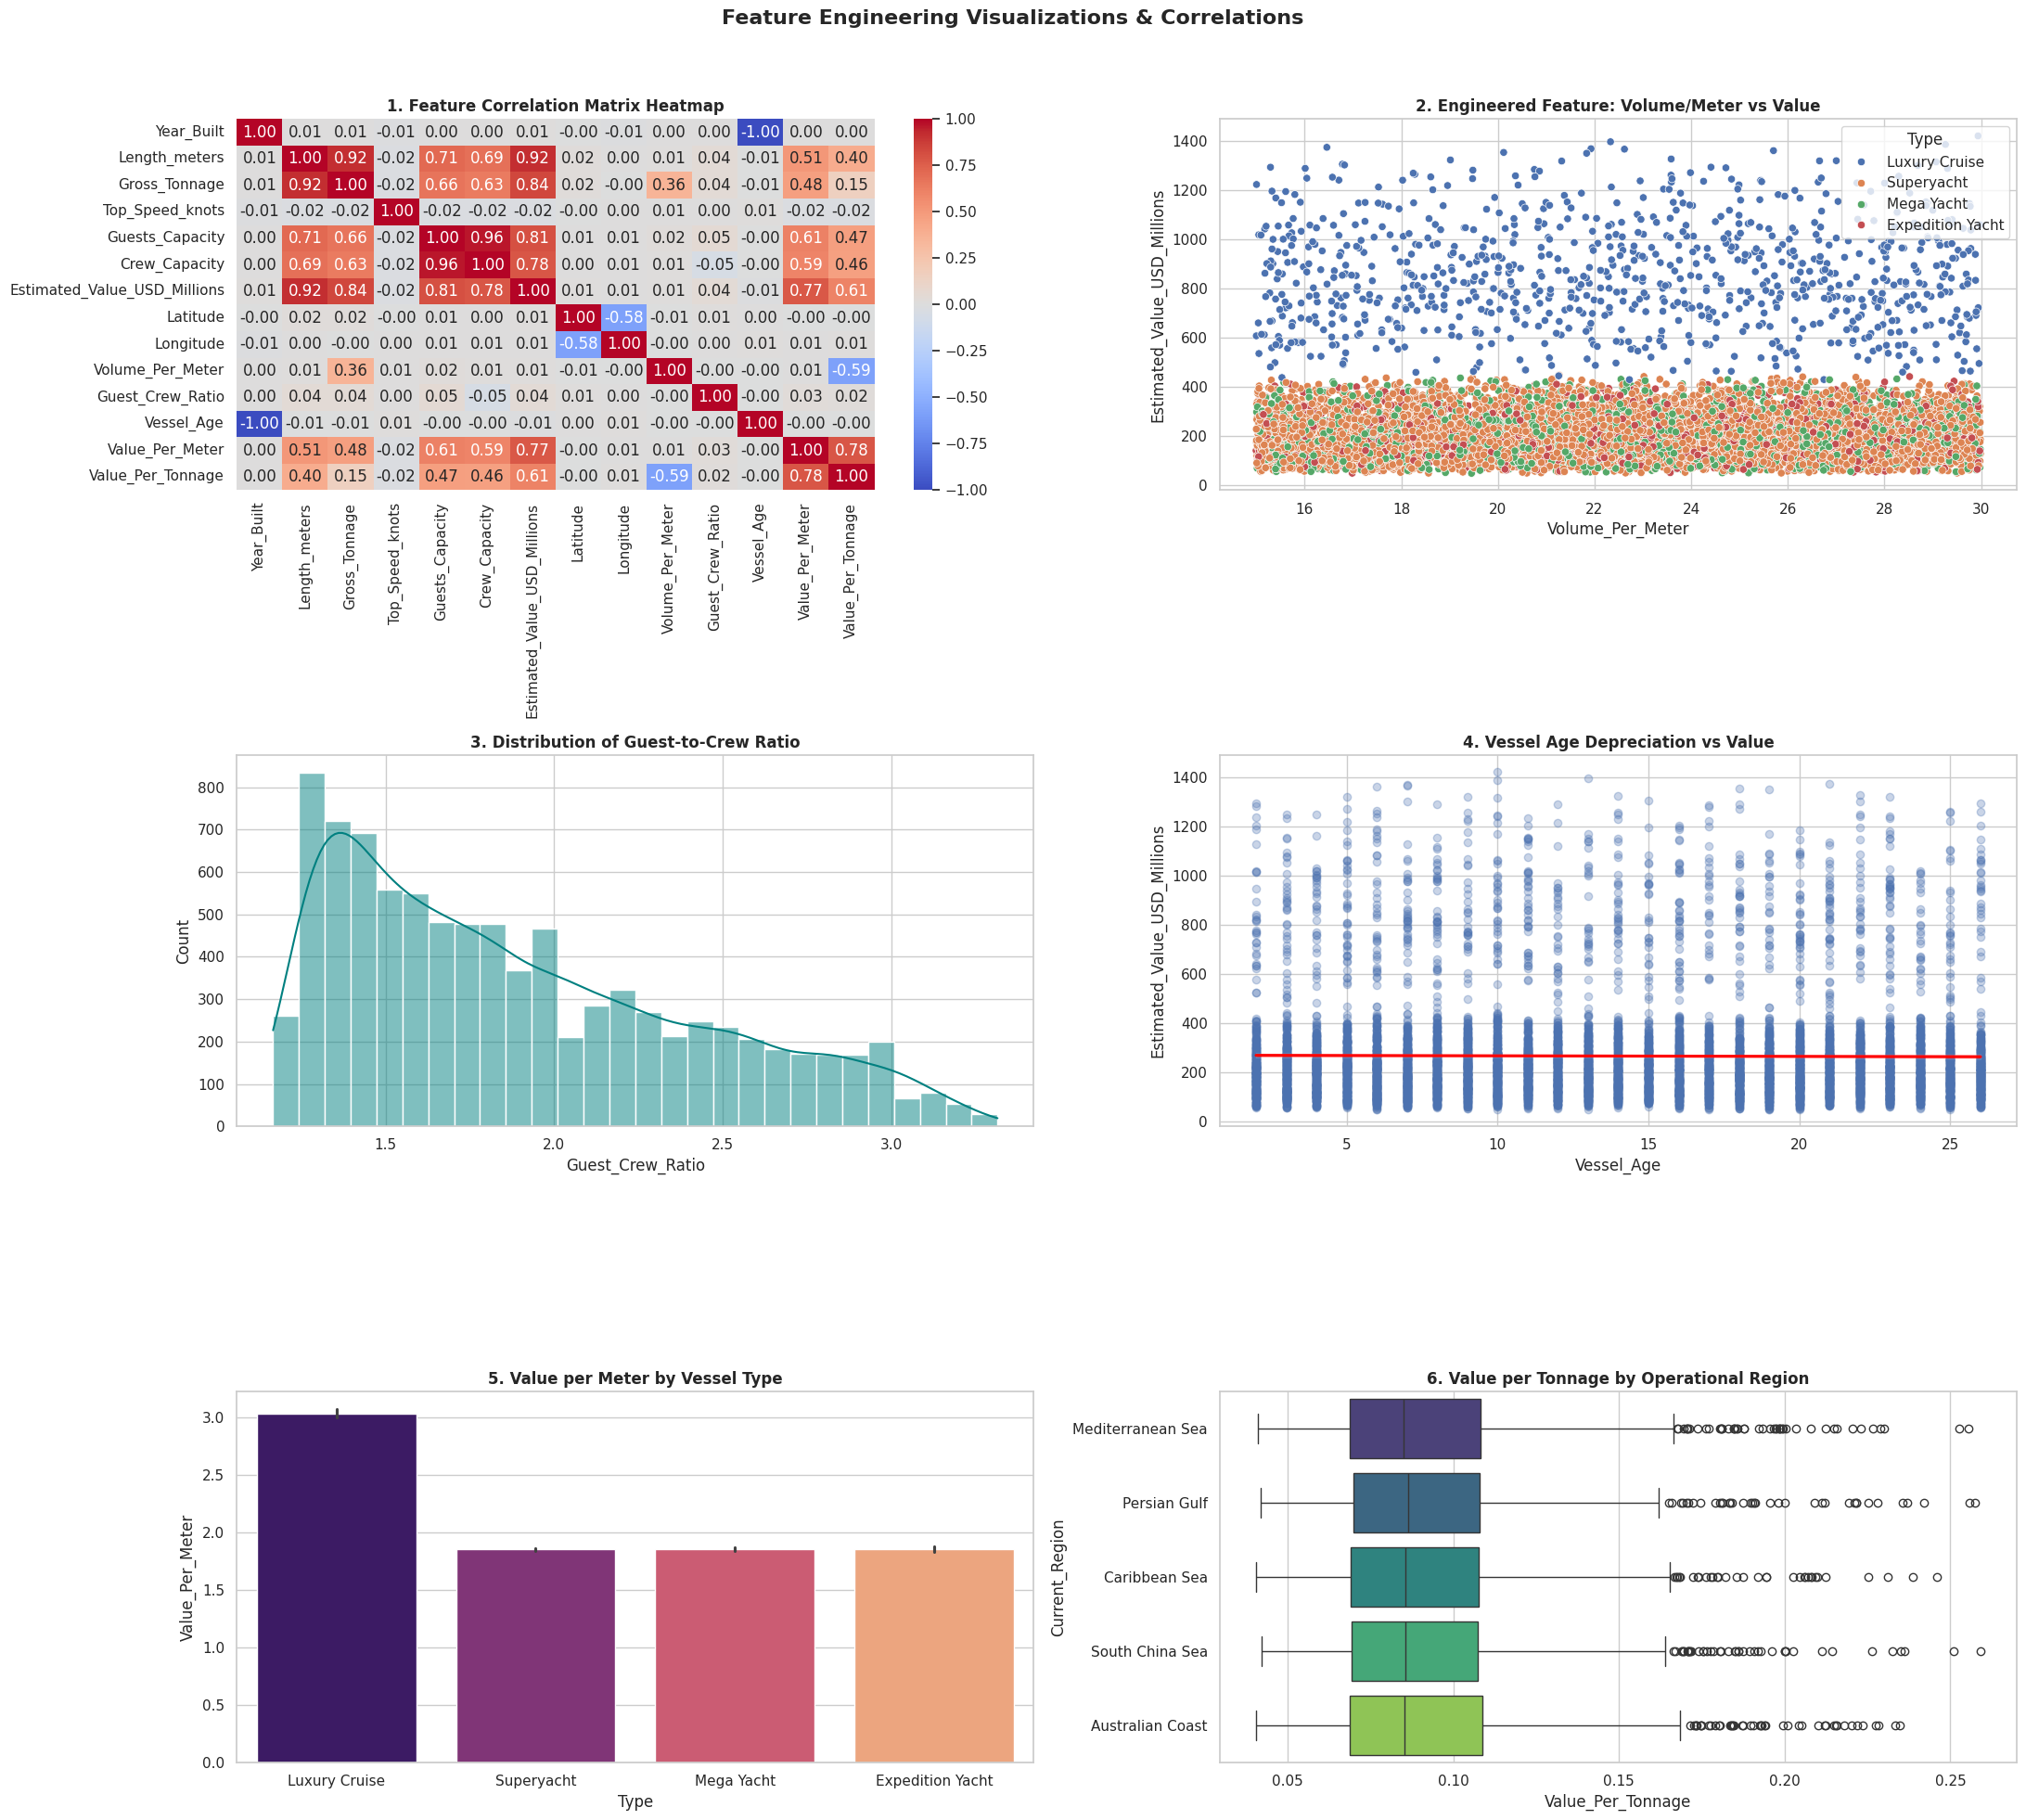


DESCRIPTION OF FEATURE ENGINEERING PLOTS:
--------------------------------------------------------------------------------
1. Correlation Heatmap: Uncovers collinearity and strong predictors for Target valuation.
2. Volume/Meter vs Value: Tests engineered structural density relationship against asset worth.
3. Guest/Crew Ratio: Measures luxury service levels (lower ratio indicates higher luxury).
4. Age Depreciation Plot: Fits linear regression showing valuation impact of vessel age.
5. Value/Meter by Type: Normalizes monetary value by vessel length across categories.
6. Value/Tonnage by Region: Compares spatial valuation intensity per volume unit.
--------------------------------------------------------------------------------



In [12]:
# ==============================================================================
# FEATURE ENGINEERING PLOTS
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Feature Engineering Pipeline
df_fe = df.copy()

# Feature 1: Volume Per Meter
df_fe['Volume_Per_Meter'] = df_fe['Gross_Tonnage'] / (df_fe['Length_meters'] + 1e-5)

# Feature 2: Guest to Crew Ratio
df_fe['Guest_Crew_Ratio'] = df_fe['Guests_Capacity'] / (df_fe['Crew_Capacity'] + 1)

# Feature 3: Vessel Age
df_fe['Vessel_Age'] = 2026 - df_fe['Year_Built']

# Feature 4: Value per Meter
df_fe['Value_Per_Meter'] = df_fe['Estimated_Value_USD_Millions'] / (df_fe['Length_meters'] + 1e-5)

# Feature 5: Value per Tonnage
df_fe['Value_Per_Tonnage'] = df_fe['Estimated_Value_USD_Millions'] / (df_fe['Gross_Tonnage'] + 1e-5)

fig, axes = plt.subplots(3, 2, figsize=(22, 20))
fig.suptitle("Feature Engineering Visualizations & Correlations", fontsize=16, fontweight='bold')

# Plot 1: Correlation Heatmap
num_cols = df_fe.select_dtypes(include=['float64', 'int64']).columns
corr_matrix = df_fe[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', ax=axes[0, 0], cbar=True)
axes[0, 0].set_title("1. Feature Correlation Matrix Heatmap", fontweight='bold')

# Plot 2: Volume Per Meter vs Value
sns.scatterplot(data=df_fe, x='Volume_Per_Meter', y='Estimated_Value_USD_Millions', hue='Type', ax=axes[0, 1])
axes[0, 1].set_title("2. Engineered Feature: Volume/Meter vs Value", fontweight='bold')

# Plot 3: Guest-Crew Ratio Distribution
sns.histplot(df_fe['Guest_Crew_Ratio'], kde=True, ax=axes[1, 0], color='teal')
axes[1, 0].set_title("3. Distribution of Guest-to-Crew Ratio", fontweight='bold')

# Plot 4: Vessel Age vs Valuation
sns.regplot(data=df_fe, x='Vessel_Age', y='Estimated_Value_USD_Millions', ax=axes[1, 1], scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
axes[1, 1].set_title("4. Vessel Age Depreciation vs Value", fontweight='bold')

# Plot 5: Value per Meter by Type
sns.barplot(data=df_fe, x='Type', y='Value_Per_Meter', ax=axes[2, 0], palette='magma')
axes[2, 0].set_title("5. Value per Meter by Vessel Type", fontweight='bold')

# Plot 6: Value per Tonnage across Regions
sns.boxplot(data=df_fe, x='Value_Per_Tonnage', y='Current_Region', ax=axes[2, 1], palette='viridis')
axes[2, 1].set_title("6. Value per Tonnage by Operational Region", fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("""
DESCRIPTION OF FEATURE ENGINEERING PLOTS:
--------------------------------------------------------------------------------
1. Correlation Heatmap: Uncovers collinearity and strong predictors for Target valuation.
2. Volume/Meter vs Value: Tests engineered structural density relationship against asset worth.
3. Guest/Crew Ratio: Measures luxury service levels (lower ratio indicates higher luxury).
4. Age Depreciation Plot: Fits linear regression showing valuation impact of vessel age.
5. Value/Meter by Type: Normalizes monetary value by vessel length across categories.
6. Value/Tonnage by Region: Compares spatial valuation intensity per volume unit.
--------------------------------------------------------------------------------
""")

/tmp/ipykernel_604/3345766216.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


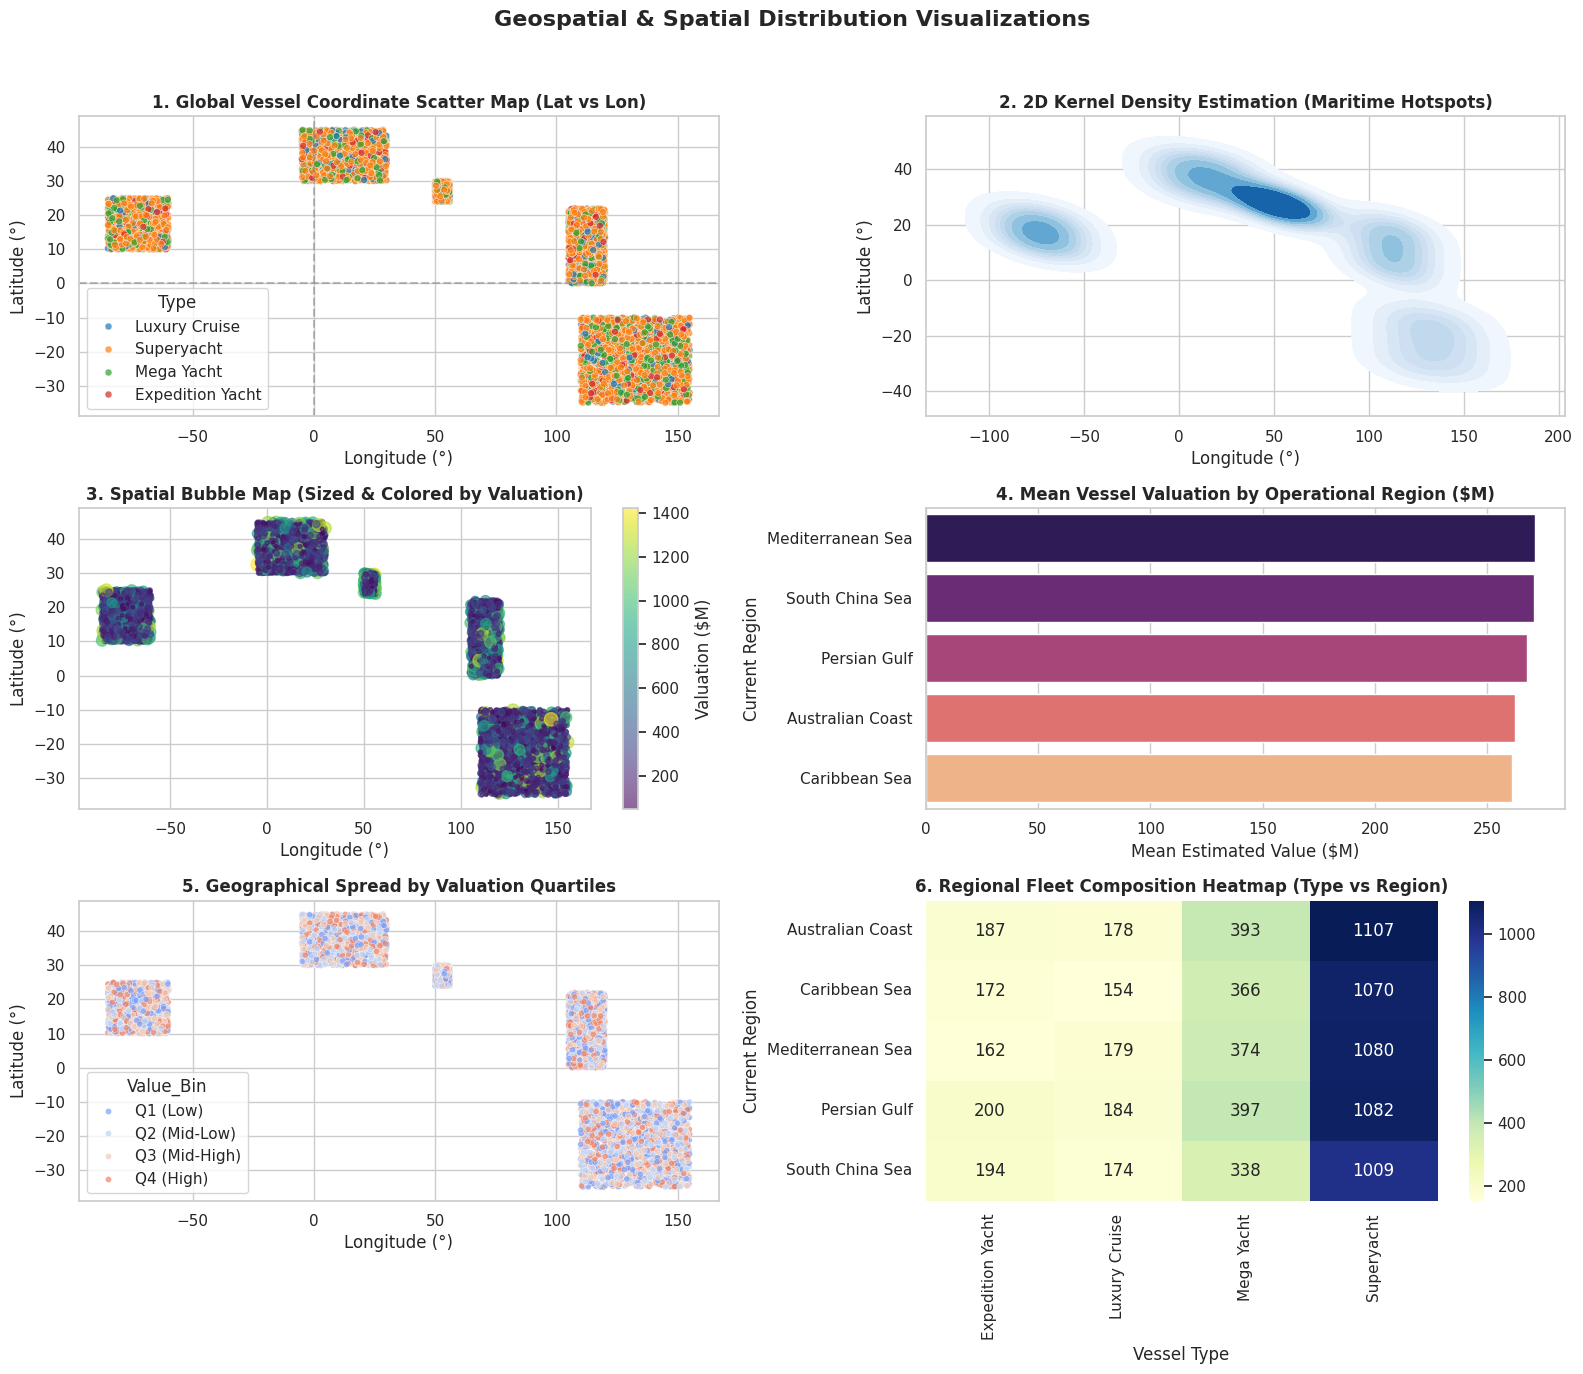


DESCRIPTION OF GEOSPATIAL PLOTS:
--------------------------------------------------------------------------------
1. Global Coordinate Scatter Map: Maps raw GPS coordinates (Lat/Lon) to visualize global fleet positioning.
2. 2D Kernel Density Map: Creates a smooth 2D density contour highlighting maritime traffic density hotspots.
3. Spatial Bubble Map: Scales point marker sizes and colors by vessel value to isolate high-worth clusters.
4. Mean Valuation by Region: Bar chart aggregating monetary valuation across maritime operating sectors.
5. Geographical Quartile Spread: Examines spatial distribution of assets across four financial value tiers.
6. Fleet Composition Heatmap: Evaluates regional vessel concentrations across different categories.
--------------------------------------------------------------------------------



In [15]:
# ==============================================================================
# GEOSPATIAL ANALYSIS PLOTS
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Step 1: Load dataset dynamically using the kagglehub downloaded path
try:
    data_dir = thinukakusalmith06_global_superyachts_and_luxury_cruise_spatial_dataset_path
    file_path = os.path.join(data_dir, 'Global_Superyachts_and_Cruises.csv')
except NameError:
    file_path = 'Global_Superyachts_and_Cruises.csv'

df = pd.read_csv(file_path)

# Pre-calculate spatial density metrics & price bins for geospatial plotting
df['Value_Bin'] = pd.qcut(df['Estimated_Value_USD_Millions'], q=4, labels=['Q1 (Low)', 'Q2 (Mid-Low)', 'Q3 (Mid-High)', 'Q4 (High)'])

# Setup 3x2 grid figure layout
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
fig.suptitle("Geospatial & Spatial Distribution Visualizations", fontsize=16, fontweight='bold')

# ------------------------------------------------------------------------------
# Plot 1: World Spatial Scatter Map of Vessel Locations
# ------------------------------------------------------------------------------
sns.scatterplot(
    data=df, x='Longitude', y='Latitude', hue='Type',
    ax=axes[0, 0], palette='tab10', alpha=0.7, s=25
)
axes[0, 0].set_title("1. Global Vessel Coordinate Scatter Map (Lat vs Lon)", fontweight='bold')
axes[0, 0].set_xlabel("Longitude (°)")
axes[0, 0].set_ylabel("Latitude (°)")
axes[0, 0].axhline(0, color='gray', linestyle='--', alpha=0.5)
axes[0, 0].axvline(0, color='gray', linestyle='--', alpha=0.5)

# ------------------------------------------------------------------------------
# Plot 2: Spatial Vessel Concentration Density Contour (2D KDE)
# ------------------------------------------------------------------------------
sns.kdeplot(
    data=df, x='Longitude', y='Latitude',
    ax=axes[0, 1], cmap='Blues', fill=True, thresh=0.05, levels=10
)
axes[0, 1].set_title("2. 2D Kernel Density Estimation (Maritime Hotspots)", fontweight='bold')
axes[0, 1].set_xlabel("Longitude (°)")
axes[0, 1].set_ylabel("Latitude (°)")

# ------------------------------------------------------------------------------
# Plot 3: Geographic Valuation Bubble Map
# ------------------------------------------------------------------------------
scatter = axes[1, 0].scatter(
    df['Longitude'], df['Latitude'],
    c=df['Estimated_Value_USD_Millions'], cmap='viridis',
    s=df['Estimated_Value_USD_Millions'] / 15, alpha=0.6
)
cbar = fig.colorbar(scatter, ax=axes[1, 0])
cbar.set_label("Valuation ($M)")
axes[1, 0].set_title("3. Spatial Bubble Map (Sized & Colored by Valuation)", fontweight='bold')
axes[1, 0].set_xlabel("Longitude (°)")
axes[1, 0].set_ylabel("Latitude (°)")

# ------------------------------------------------------------------------------
# Plot 4: Average Vessel Valuation by Geographic Region
# ------------------------------------------------------------------------------
region_val = df.groupby('Current_Region')['Estimated_Value_USD_Millions'].mean().sort_values(ascending=False).reset_index()
sns.barplot(
    data=region_val, x='Estimated_Value_USD_Millions', y='Current_Region',
    ax=axes[1, 1], palette='magma'
)
axes[1, 1].set_title("4. Mean Vessel Valuation by Operational Region ($M)", fontweight='bold')
axes[1, 1].set_xlabel("Mean Estimated Value ($M)")
axes[1, 1].set_ylabel("Current Region")

# ------------------------------------------------------------------------------
# Plot 5: Spatial Distribution Across Valuation Quartiles
# ------------------------------------------------------------------------------
sns.scatterplot(
    data=df, x='Longitude', y='Latitude', hue='Value_Bin',
    ax=axes[2, 0], palette='coolwarm', alpha=0.7, s=20
)
axes[2, 0].set_title("5. Geographical Spread by Valuation Quartiles", fontweight='bold')
axes[2, 0].set_xlabel("Longitude (°)")
axes[2, 0].set_ylabel("Latitude (°)")

# ------------------------------------------------------------------------------
# Plot 6: Regional Vessel Type Composition Matrix (Heatmap)
# ------------------------------------------------------------------------------
region_type_ct = pd.crosstab(df['Current_Region'], df['Type'])
sns.heatmap(
    region_type_ct, annot=True, fmt='d', cmap='YlGnBu',
    ax=axes[2, 1], cbar=True
)
axes[2, 1].set_title("6. Regional Fleet Composition Heatmap (Type vs Region)", fontweight='bold')
axes[2, 1].set_xlabel("Vessel Type")
axes[2, 1].set_ylabel("Current Region")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("""
DESCRIPTION OF GEOSPATIAL PLOTS:
--------------------------------------------------------------------------------
1. Global Coordinate Scatter Map: Maps raw GPS coordinates (Lat/Lon) to visualize global fleet positioning.
2. 2D Kernel Density Map: Creates a smooth 2D density contour highlighting maritime traffic density hotspots.
3. Spatial Bubble Map: Scales point marker sizes and colors by vessel value to isolate high-worth clusters.
4. Mean Valuation by Region: Bar chart aggregating monetary valuation across maritime operating sectors.
5. Geographical Quartile Spread: Examines spatial distribution of assets across four financial value tiers.
6. Fleet Composition Heatmap: Evaluates regional vessel concentrations across different categories.
--------------------------------------------------------------------------------
""")

/tmp/ipykernel_604/1311724789.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=res_df, x='R2_Score', y='Model', ax=axes[0, 0], palette='crest')


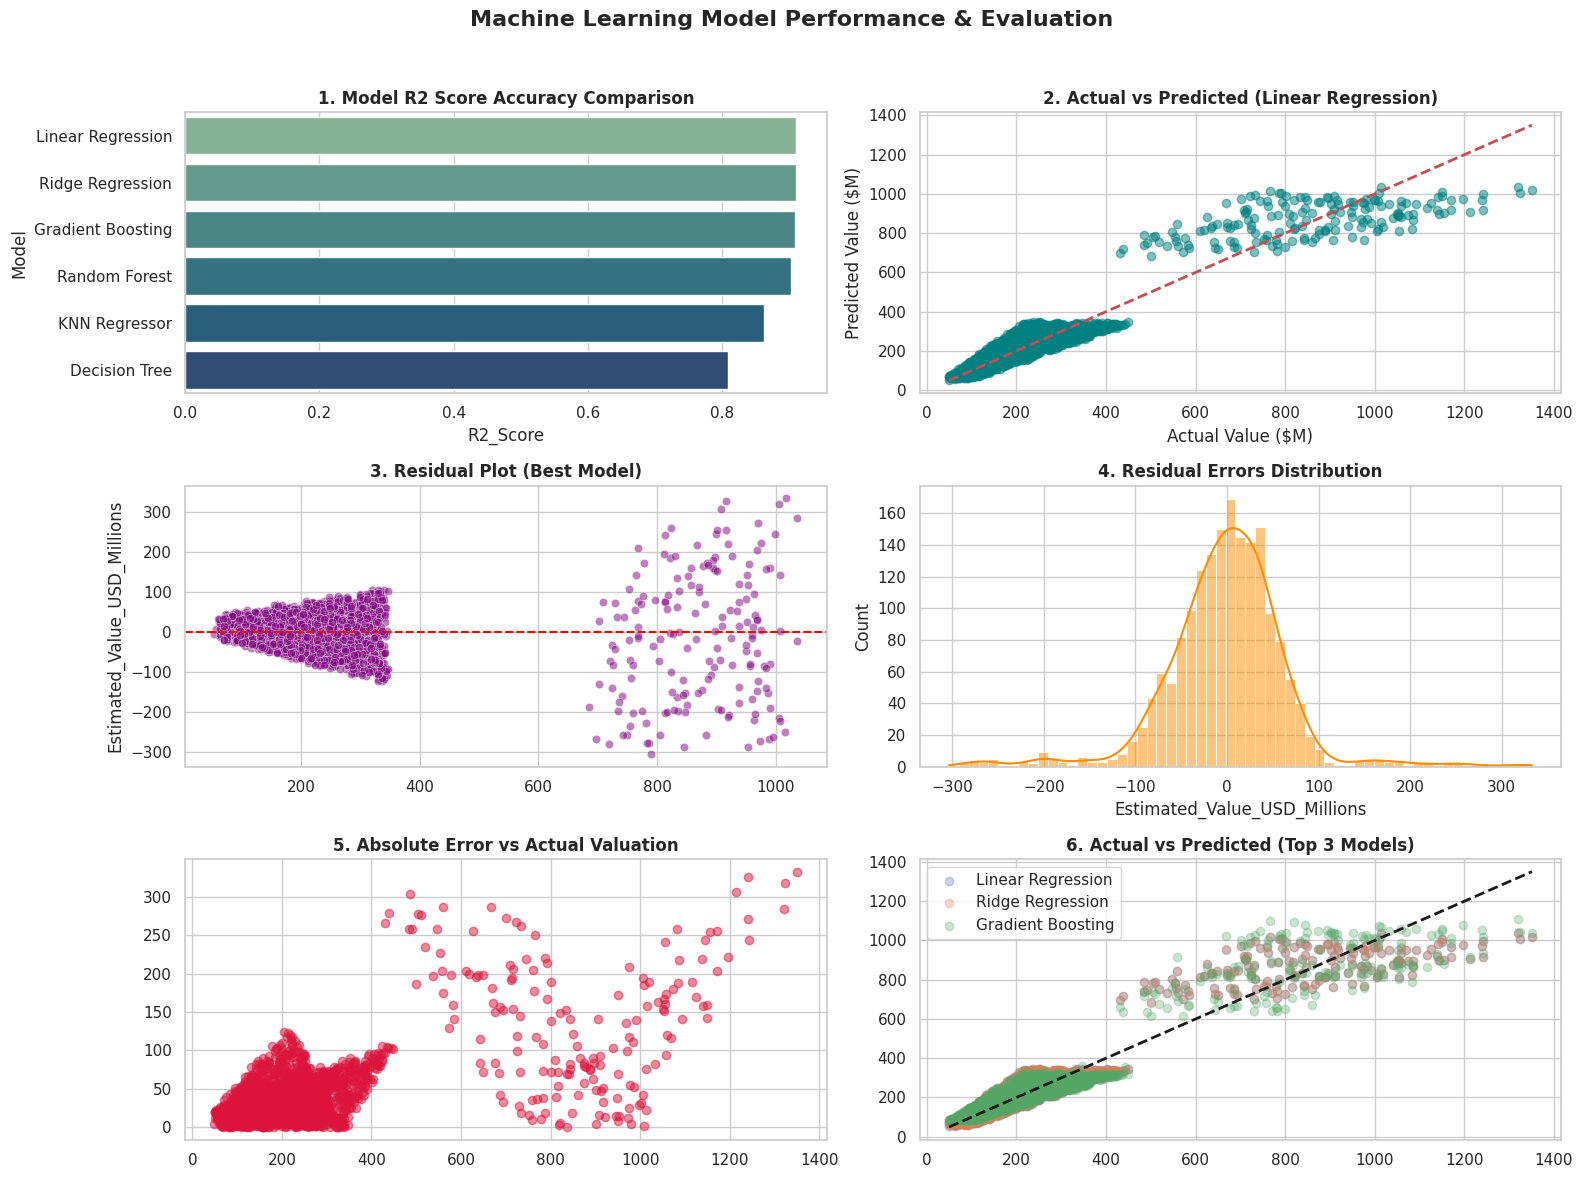


DESCRIPTION OF ML EVALUATION PLOTS:
--------------------------------------------------------------------------------
1. R2 Score Comparison: Ranks all tested Machine Learning models by predictive accuracy.
2. Actual vs Predicted Plot: Compares target values against model predictions along 1:1 identity line.
3. Residual Plot: Evaluates homoscedasticity and residual randomness around zero error.
4. Residual Distribution: Verifies whether model prediction errors are normally distributed.
5. Absolute Error vs Target: Detects if prediction error grows as vessel valuation increases.
6. Top 3 Overlay Plot: Compares forecast precision across top competing algorithms.
--------------------------------------------------------------------------------



In [18]:
# ==============================================================================
# ML MODELS & EVALUATION PLOTS
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor

# Target variable definition
# Make sure to drop all target-derived categories, anomalies, and labels that are not raw features
columns_to_drop = [
    'Vessel_ID', 'Vessel_Name', 'Estimated_Value_USD_Millions', 'Era',
    'Value_Bin', 'iso_anomaly', 'iso_score', 'lof_anomaly', 'ee_anomaly',
    'consensus_anomalies', 'kmeans_cluster', 'dbscan_cluster', 'pca1', 'pca2'
]
X = df.drop(columns=columns_to_drop, errors='ignore')
y = df['Estimated_Value_USD_Millions']

# Preprocessing pipeline
categorical_features = ['Type', 'Builder', 'Engine_Type', 'Current_Region']
numerical_features = [col for col in X.columns if col not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=50, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=50, random_state=42),
    'KNN Regressor': KNeighborsRegressor()
}

results = {}
predictions = {}

for name, model in models.items():
    clf = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    r2 = r2_score(y_test, preds)
    results[name] = r2
    predictions[name] = preds

# Visualization of ML Performance
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
fig.suptitle("Machine Learning Model Performance & Evaluation", fontsize=16, fontweight='bold')

# Plot 1: Model Accuracy (R2 Score) Comparison Bar Chart
res_df = pd.DataFrame(list(results.items()), columns=['Model', 'R2_Score']).sort_values(by='R2_Score', ascending=False)
sns.barplot(data=res_df, x='R2_Score', y='Model', ax=axes[0, 0], palette='crest')
axes[0, 0].set_title("1. Model R2 Score Accuracy Comparison", fontweight='bold')

# Plot 2: Actual vs Predicted Scatter Plot (Best Model)
best_model_name = res_df.iloc[0]['Model']
axes[0, 1].scatter(y_test, predictions[best_model_name], alpha=0.5, color='teal')
axes[0, 1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0, 1].set_title(f"2. Actual vs Predicted ({best_model_name})", fontweight='bold')
axes[0, 1].set_xlabel("Actual Value ($M)")
axes[0, 1].set_ylabel("Predicted Value ($M)")

# Plot 3: Residuals Plot
residuals = y_test - predictions[best_model_name]
sns.scatterplot(x=predictions[best_model_name], y=residuals, ax=axes[1, 0], color='purple', alpha=0.5)
axes[1, 0].axhline(0, color='red', linestyle='--')
axes[1, 0].set_title("3. Residual Plot (Best Model)", fontweight='bold')

# Plot 4: Residual Distribution
sns.histplot(residuals, kde=True, ax=axes[1, 1], color='darkorange')
axes[1, 1].set_title("4. Residual Errors Distribution", fontweight='bold')

# Plot 5: Prediction Error vs Actual Value
axes[2, 0].scatter(y_test, np.abs(residuals), color='crimson', alpha=0.5)
axes[2, 0].set_title("5. Absolute Error vs Actual Valuation", fontweight='bold')

# Plot 6: Comparative Prediction Spread across Top 3 Models
top3 = res_df.head(3)['Model'].tolist()
for m in top3:
    axes[2, 1].scatter(y_test, predictions[m], alpha=0.3, label=m)
axes[2, 1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
axes[2, 1].set_title("6. Actual vs Predicted (Top 3 Models)", fontweight='bold')
axes[2, 1].legend()

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("""
DESCRIPTION OF ML EVALUATION PLOTS:
--------------------------------------------------------------------------------
1. R2 Score Comparison: Ranks all tested Machine Learning models by predictive accuracy.
2. Actual vs Predicted Plot: Compares target values against model predictions along 1:1 identity line.
3. Residual Plot: Evaluates homoscedasticity and residual randomness around zero error.
4. Residual Distribution: Verifies whether model prediction errors are normally distributed.
5. Absolute Error vs Target: Detects if prediction error grows as vessel valuation increases.
6. Top 3 Overlay Plot: Compares forecast precision across top competing algorithms.
--------------------------------------------------------------------------------
""")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 13.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=19673c800862b1970acfd88413a776ba725980de3bd3319a58103be72d1a1ce2
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


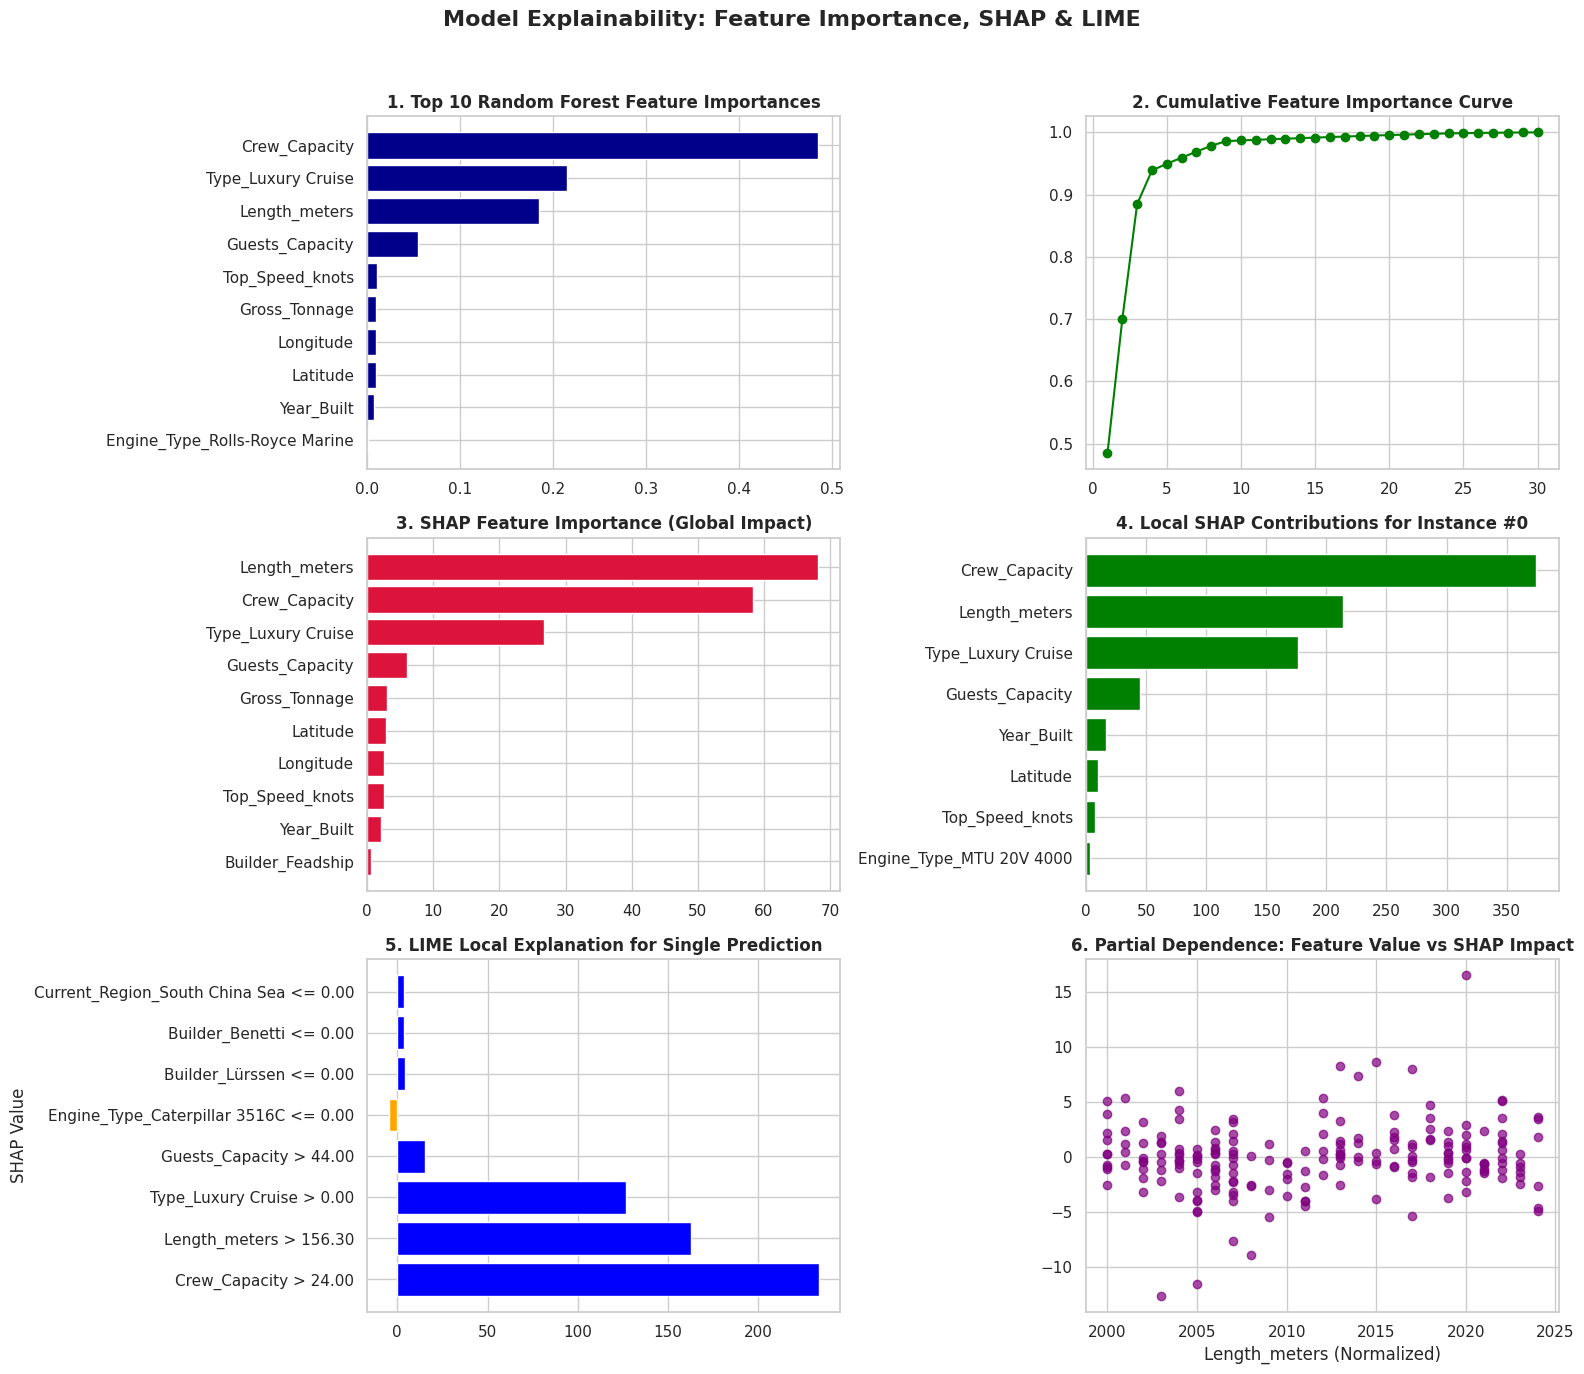


DESCRIPTION OF EXPLAINABILITY PLOTS:
--------------------------------------------------------------------------------
1. Random Forest Feature Importance: Ranks top 10 features directly driving tree split decisions.
2. Cumulative Importance: Visualizes how many top features capture total model variance.
3. SHAP Summary Plot: Quantifies average absolute SHAP impact of features across samples.
4. Local SHAP Instance: Shows specific positive/negative feature forces driving a single vessel's value.
5. LIME Local Explanation: Fits a local surrogate linear model around one sample to show local feature impact.
6. Partial Dependence SHAP Scatter: Maps how specific variations in Vessel Length alter SHAP valuation impact.
--------------------------------------------------------------------------------



In [20]:
# ==============================================================================
# FEATURE IMPORTANCE PLOTS
# ==============================================================================

!pip install lime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
import shap
from lime import lime_tabular

# Fit a dedicated Random Forest model on encoded feature matrix
rf = RandomForestRegressor(n_estimators=50, random_state=42)
X_trans = preprocessor.fit_transform(X)
ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
all_feature_names = list(numerical_features) + list(ohe_feature_names)

rf.fit(X_trans, y)

fig, axes = plt.subplots(3, 2, figsize=(16, 14))
fig.suptitle("Model Explainability: Feature Importance, SHAP & LIME", fontsize=16, fontweight='bold')

# Plot 1: Tree-Based Feature Importance (Top 10)
importances = rf.feature_importances_
indices = np.argsort(importances)[-10:]
axes[0, 0].barh(range(len(indices)), importances[indices], align='center', color='darkblue')
axes[0, 0].set_yticks(range(len(indices)))
axes[0, 0].set_yticklabels([all_feature_names[i] for i in indices])
axes[0, 0].set_title("1. Top 10 Random Forest Feature Importances", fontweight='bold')

# Plot 2: Cumulative Feature Importance
sorted_importances = np.sort(importances)[::-1]
cum_sum = np.cumsum(sorted_importances)
axes[0, 1].plot(range(1, len(cum_sum) + 1), cum_sum, marker='o', color='green')
axes[0, 1].set_title("2. Cumulative Feature Importance Curve", fontweight='bold')

# Plot 3: SHAP Summary Bar Plot (Mean |SHAP Value|)
explainer = shap.TreeExplainer(rf)
shap_sample = X_trans[:200]
shap_values = explainer.shap_values(shap_sample)

mean_abs_shap = np.abs(shap_values).mean(axis=0)
shap_indices = np.argsort(mean_abs_shap)[-10:]
axes[1, 0].barh(range(len(shap_indices)), mean_abs_shap[shap_indices], color='crimson')
axes[1, 0].set_yticks(range(len(shap_indices)))
axes[1, 0].set_yticklabels([all_feature_names[i] for i in shap_indices])
axes[1, 0].set_title("3. SHAP Feature Importance (Global Impact)", fontweight='bold')

# Plot 4: SHAP Force Plot / Waterfall Representation for single prediction instance
inst_idx = 0
instance_shap = shap_values[inst_idx]
top_inst_idx = np.argsort(np.abs(instance_shap))[-8:]
colors = ['green' if x > 0 else 'red' for x in instance_shap[top_inst_idx]]
axes[1, 1].barh(range(len(top_inst_idx)), instance_shap[top_inst_idx], color=colors)
axes[1, 1].set_yticks(range(len(top_inst_idx)))
axes[1, 1].set_yticklabels([all_feature_names[i] for i in top_inst_idx])
axes[1, 1].set_title(f"4. Local SHAP Contributions for Instance #{inst_idx}", fontweight='bold')

# Plot 5: LIME Local Explanation Visualization
lime_explainer = lime_tabular.LimeTabularExplainer(
    training_data=X_trans,
    feature_names=all_feature_names,
    mode='regression',
    random_state=42
)
exp = lime_explainer.explain_instance(X_trans[0], rf.predict, num_features=8)
lime_list = exp.as_list()
lime_feats = [x[0] for x in lime_list]
lime_weights = [x[1] for x in lime_list]

colors_lime = ['blue' if w > 0 else 'orange' for w in lime_weights]
axes[2, 0].barh(lime_feats, lime_weights, color=colors_lime)
axes[2, 0].set_title("5. LIME Local Explanation for Single Prediction", fontweight='bold')

# Plot 6: Partial Dependence Plot Proxy (Length vs Value SHAP interaction)
axes[2, 1].scatter(X_trans[:200, 0], shap_values[:, 0], color='purple', alpha=0.7)
axes[2, 1].set_title("6. Partial Dependence: Feature Value vs SHAP Impact", fontweight='bold')
axes[2, 1].set_xlabel("Length_meters (Normalized)")
axes[2, 0].set_ylabel("SHAP Value")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("""
DESCRIPTION OF EXPLAINABILITY PLOTS:
--------------------------------------------------------------------------------
1. Random Forest Feature Importance: Ranks top 10 features directly driving tree split decisions.
2. Cumulative Importance: Visualizes how many top features capture total model variance.
3. SHAP Summary Plot: Quantifies average absolute SHAP impact of features across samples.
4. Local SHAP Instance: Shows specific positive/negative feature forces driving a single vessel's value.
5. LIME Local Explanation: Fits a local surrogate linear model around one sample to show local feature impact.
6. Partial Dependence SHAP Scatter: Maps how specific variations in Vessel Length alter SHAP valuation impact.
--------------------------------------------------------------------------------
""")

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


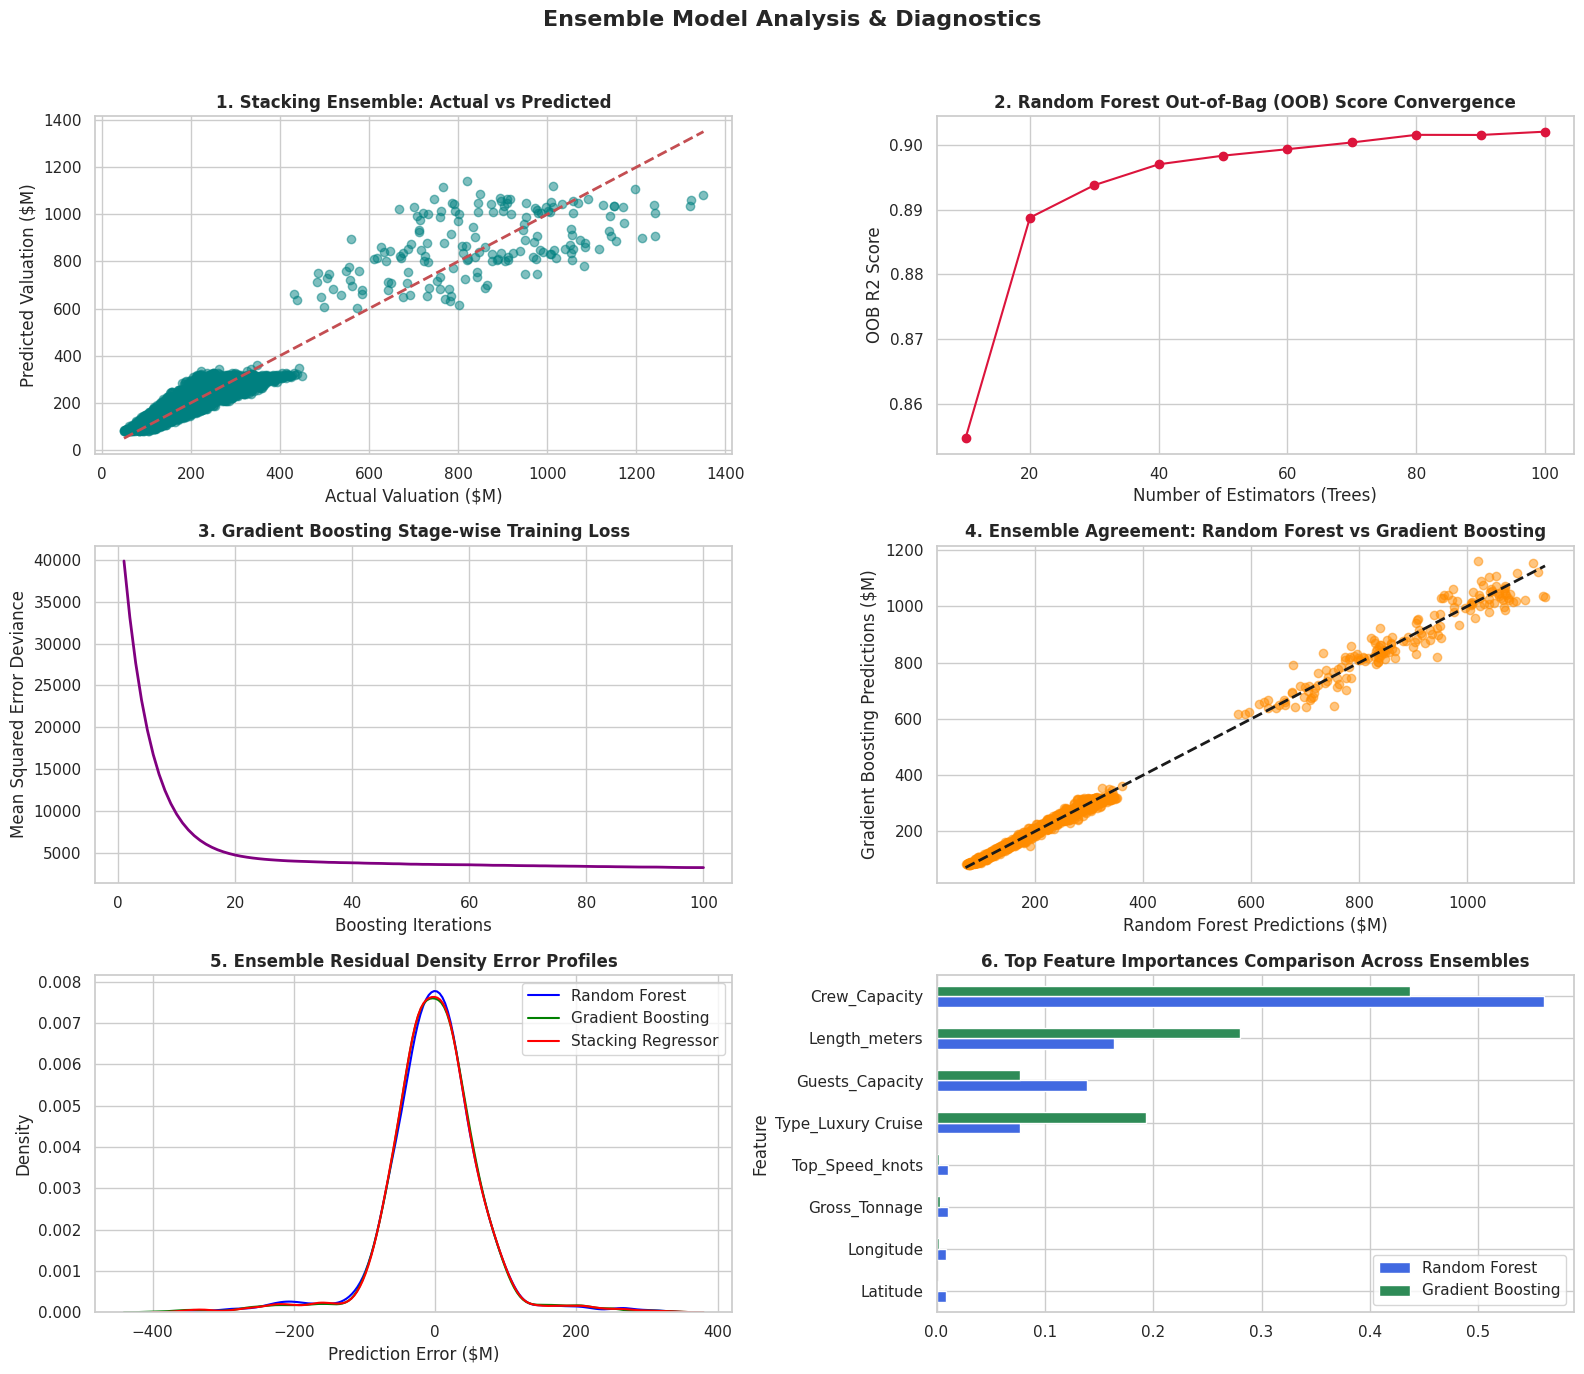


DESCRIPTION OF ENSEMBLE PLOTS:
--------------------------------------------------------------------------------
1. Stacking Actual vs Predicted: Tests multi-model Stacking Regressor predictions against ground truth target values.
2. OOB Score Convergence: Evaluates generalization error performance stability as tree counts increase in Random Forest.
3. Gradient Boosting Stage-wise Loss: Tracks model loss decrease across boosting iterations to verify learning rate tuning.
4. Ensemble Model Agreement: Measures consistency and prediction variance between distinct ensemble architectures.
5. Ensemble Residual Density Error: Overlays prediction error distributions to highlight variance reduction in stacked models.
6. Feature Importances Comparison: Compares feature weight attributions between bagging and boosting ensembles.
--------------------------------------------------------------------------------



In [22]:
# ==============================================================================
# ENSEMBLE MODELS & PLOTS
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Load and prepare dataset dynamically
try:
    data_dir = thinukakusalmith06_global_superyachts_and_luxury_cruise_spatial_dataset_path
    file_path = os.path.join(data_dir, 'Global_Superyachts_and_Cruises.csv')
except NameError:
    file_path = 'Global_Superyachts_and_Cruises.csv'

df = pd.read_csv(file_path)

X = df.drop(columns=['Vessel_ID', 'Vessel_Name', 'Estimated_Value_USD_Millions'])
y = df['Estimated_Value_USD_Millions']

cat_cols = ['Type', 'Builder', 'Engine_Type', 'Current_Region']
num_cols = [c for c in X.columns if c not in cat_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

X_trans = preprocessor.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_trans, y, test_size=0.2, random_state=42)

# Train individual ensemble models
rf = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)
gb = GradientBoostingRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)

estimators = [('rf', rf), ('gb', gb)]
stacking = StackingRegressor(estimators=estimators, final_estimator=Ridge()).fit(X_train, y_train)

preds_rf = rf.predict(X_test)
preds_gb = gb.predict(X_test)
preds_stack = stacking.predict(X_test)

# Plotting Ensemble Diagnostics
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
fig.suptitle("Ensemble Model Analysis & Diagnostics", fontsize=16, fontweight='bold')

# Plot 1: Stacking Regressor Actual vs Predicted Scatter
axes[0, 0].scatter(y_test, preds_stack, color='teal', alpha=0.5, label='Stacking Predictions')
axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0, 0].set_title("1. Stacking Ensemble: Actual vs Predicted", fontweight='bold')
axes[0, 0].set_xlabel("Actual Valuation ($M)")
axes[0, 0].set_ylabel("Predicted Valuation ($M)")

# Plot 2: OOB (Out-of-Bag) Score Convergence Curve across Estimators
rf_oob = RandomForestRegressor(oob_score=True, random_state=42, warm_start=True)
oob_scores = []
n_trees_range = range(10, 110, 10)
for n in n_trees_range:
    rf_oob.set_params(n_estimators=n)
    rf_oob.fit(X_train, y_train)
    oob_scores.append(rf_oob.oob_score_)

axes[0, 1].plot(n_trees_range, oob_scores, marker='o', color='crimson')
axes[0, 1].set_title("2. Random Forest Out-of-Bag (OOB) Score Convergence", fontweight='bold')
axes[0, 1].set_xlabel("Number of Estimators (Trees)")
axes[0, 1].set_ylabel("OOB R2 Score")

# Plot 3: Gradient Boosting Stage-wise Training Loss (Deviance)
train_deviance = gb.train_score_
axes[1, 0].plot(np.arange(len(train_deviance)) + 1, train_deviance, color='purple', lw=2)
axes[1, 0].set_title("3. Gradient Boosting Stage-wise Training Loss", fontweight='bold')
axes[1, 0].set_xlabel("Boosting Iterations")
axes[1, 0].set_ylabel("Mean Squared Error Deviance")

# Plot 4: Prediction Agreement Matrix Between Individual Ensemble Models
axes[1, 1].scatter(preds_rf, preds_gb, alpha=0.5, color='darkorange')
axes[1, 1].plot([preds_rf.min(), preds_rf.max()], [preds_rf.min(), preds_rf.max()], 'k--', lw=2)
axes[1, 1].set_title("4. Ensemble Agreement: Random Forest vs Gradient Boosting", fontweight='bold')
axes[1, 1].set_xlabel("Random Forest Predictions ($M)")
axes[1, 1].set_ylabel("Gradient Boosting Predictions ($M)")

# Plot 5: Model Error Residual Distribution Comparison across Ensembles
res_rf = y_test - preds_rf
res_gb = y_test - preds_gb
res_stack = y_test - preds_stack

sns.kdeplot(res_rf, ax=axes[2, 0], label='Random Forest', color='blue')
sns.kdeplot(res_gb, ax=axes[2, 0], label='Gradient Boosting', color='green')
sns.kdeplot(res_stack, ax=axes[2, 0], label='Stacking Regressor', color='red')
axes[2, 0].set_title("5. Ensemble Residual Density Error Profiles", fontweight='bold')
axes[2, 0].set_xlabel("Prediction Error ($M)")
axes[2, 0].legend()

# Plot 6: Feature Importances Variance across Random Forest & Gradient Boosting
ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
all_feature_names = list(num_cols) + list(ohe_feature_names)
top_idx = np.argsort(rf.feature_importances_)[-8:]

comp_df = pd.DataFrame({
    'Feature': [all_feature_names[i] for i in top_idx],
    'Random Forest': rf.feature_importances_[top_idx],
    'Gradient Boosting': gb.feature_importances_[top_idx]
}).set_index('Feature')

comp_df.plot(kind='barh', ax=axes[2, 1], color=['royalblue', 'seagreen'])
axes[2, 1].set_title("6. Top Feature Importances Comparison Across Ensembles", fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("""
DESCRIPTION OF ENSEMBLE PLOTS:
--------------------------------------------------------------------------------
1. Stacking Actual vs Predicted: Tests multi-model Stacking Regressor predictions against ground truth target values.
2. OOB Score Convergence: Evaluates generalization error performance stability as tree counts increase in Random Forest.
3. Gradient Boosting Stage-wise Loss: Tracks model loss decrease across boosting iterations to verify learning rate tuning.
4. Ensemble Model Agreement: Measures consistency and prediction variance between distinct ensemble architectures.
5. Ensemble Residual Density Error: Overlays prediction error distributions to highlight variance reduction in stacked models.
6. Feature Importances Comparison: Compares feature weight attributions between bagging and boosting ensembles.
--------------------------------------------------------------------------------
""")

/tmp/ipykernel_604/1132845321.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=anom_by_type, x='Type', y='iso_anomaly', ax=axes[2, 0], palette='magma')
/tmp/ipykernel_604/1132845321.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='consensus_anomalies', ax=axes[2, 1], palette='rocket')


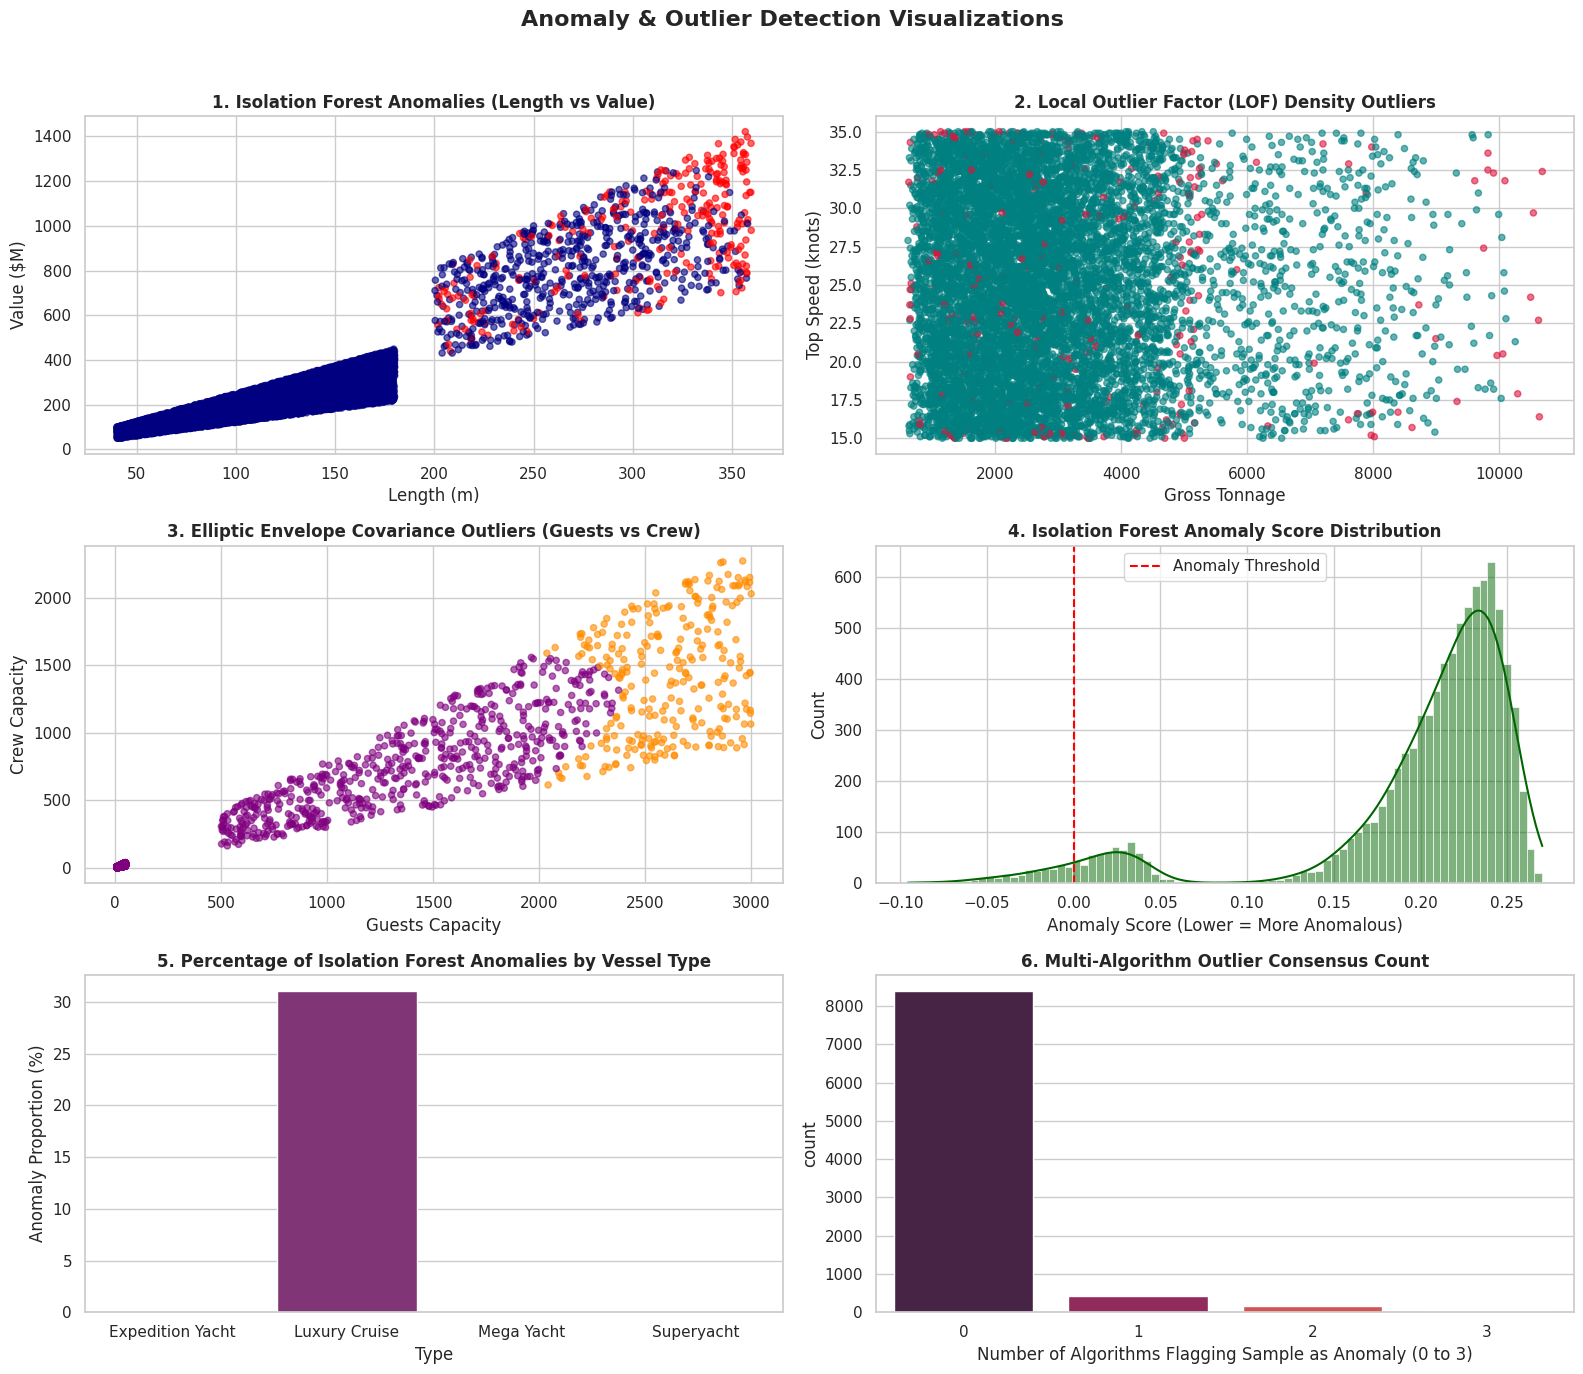


DESCRIPTION OF ANOMALY DETECTION PLOTS:
--------------------------------------------------------------------------------
1. Isolation Forest Scatter: Identifies global price-to-size structural anomalies across the fleet.
2. LOF Density Map: Locates local neighborhood density outliers comparing speed against gross tonnage.
3. Elliptic Envelope Covariance: Detects multivariate covariance outliers between guests and crew sizing.
4. Anomaly Score Distribution: Analyzes decision boundary score distribution to establish contamination thresholds.
5. Anomaly Rate by Type: Compares anomaly concentration across Superyachts vs Luxury Cruises.
6. Multi-Algorithm Consensus: Cross-validates detected outliers across 3 distinct algorithmic approaches.
--------------------------------------------------------------------------------



In [23]:
# ==============================================================================
# ANOMALY DETECTION PLOTS
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
from sklearn.preprocessing import StandardScaler

# Prepare dataset numerical columns
num_cols = ['Length_meters', 'Gross_Tonnage', 'Top_Speed_knots', 'Guests_Capacity', 'Crew_Capacity', 'Estimated_Value_USD_Millions']
X_num = StandardScaler().fit_transform(df[num_cols])

# 1. Isolation Forest
iso = IsolationForest(contamination=0.03, random_state=42)
df['iso_anomaly'] = iso.fit_predict(X_num)
df['iso_score'] = iso.decision_function(X_num)

# 2. Local Outlier Factor (LOF)
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.03)
df['lof_anomaly'] = lof.fit_predict(X_num)

# 3. Robust Covariance (Elliptic Envelope)
ee = EllipticEnvelope(contamination=0.03, random_state=42)
df['ee_anomaly'] = ee.fit_predict(X_num)

fig, axes = plt.subplots(3, 2, figsize=(16, 14))
fig.suptitle("Anomaly & Outlier Detection Visualizations", fontsize=16, fontweight='bold')

# Plot 1: Isolation Forest Bivariate Scatter (Length vs Value)
colors_iso = np.where(df['iso_anomaly'] == -1, 'red', 'navy')
axes[0, 0].scatter(df['Length_meters'], df['Estimated_Value_USD_Millions'], c=colors_iso, alpha=0.6, s=20)
axes[0, 0].set_title("1. Isolation Forest Anomalies (Length vs Value)", fontweight='bold')
axes[0, 0].set_xlabel("Length (m)")
axes[0, 0].set_ylabel("Value ($M)")

# Plot 2: Local Outlier Factor (LOF) Outlier Map (Tonnage vs Speed)
colors_lof = np.where(df['lof_anomaly'] == -1, 'crimson', 'teal')
axes[0, 1].scatter(df['Gross_Tonnage'], df['Top_Speed_knots'], c=colors_lof, alpha=0.6, s=20)
axes[0, 1].set_title("2. Local Outlier Factor (LOF) Density Outliers", fontweight='bold')
axes[0, 1].set_xlabel("Gross Tonnage")
axes[0, 1].set_ylabel("Top Speed (knots)")

# Plot 3: Elliptic Envelope Robust Covariance Boundary Outliers
colors_ee = np.where(df['ee_anomaly'] == -1, 'darkorange', 'purple')
axes[1, 0].scatter(df['Guests_Capacity'], df['Crew_Capacity'], c=colors_ee, alpha=0.6, s=20)
axes[1, 0].set_title("3. Elliptic Envelope Covariance Outliers (Guests vs Crew)", fontweight='bold')
axes[1, 0].set_xlabel("Guests Capacity")
axes[1, 0].set_ylabel("Crew Capacity")

# Plot 4: Isolation Forest Anomaly Score Distribution Histogram
sns.histplot(df['iso_score'], kde=True, ax=axes[1, 1], color='darkgreen')
axes[1, 1].axvline(0, color='red', linestyle='--', label='Anomaly Threshold')
axes[1, 1].set_title("4. Isolation Forest Anomaly Score Distribution", fontweight='bold')
axes[1, 1].set_xlabel("Anomaly Score (Lower = More Anomalous)")
axes[1, 1].legend()

# Plot 5: Anomaly Rate Proportion by Vessel Category
anom_by_type = df.groupby('Type')['iso_anomaly'].apply(lambda x: (x == -1).mean() * 100).reset_index()
sns.barplot(data=anom_by_type, x='Type', y='iso_anomaly', ax=axes[2, 0], palette='magma')
axes[2, 0].set_title("5. Percentage of Isolation Forest Anomalies by Vessel Type", fontweight='bold')
axes[2, 0].set_ylabel("Anomaly Proportion (%)")

# Plot 6: Outlier Agreement Matrix Across Detection Algorithms
df['consensus_anomalies'] = ((df['iso_anomaly'] == -1).astype(int) +
                            (df['lof_anomaly'] == -1).astype(int) +
                            (df['ee_anomaly'] == -1).astype(int))

sns.countplot(data=df, x='consensus_anomalies', ax=axes[2, 1], palette='rocket')
axes[2, 1].set_title("6. Multi-Algorithm Outlier Consensus Count", fontweight='bold')
axes[2, 1].set_xlabel("Number of Algorithms Flagging Sample as Anomaly (0 to 3)")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("""
DESCRIPTION OF ANOMALY DETECTION PLOTS:
--------------------------------------------------------------------------------
1. Isolation Forest Scatter: Identifies global price-to-size structural anomalies across the fleet.
2. LOF Density Map: Locates local neighborhood density outliers comparing speed against gross tonnage.
3. Elliptic Envelope Covariance: Detects multivariate covariance outliers between guests and crew sizing.
4. Anomaly Score Distribution: Analyzes decision boundary score distribution to establish contamination thresholds.
5. Anomaly Rate by Type: Compares anomaly concentration across Superyachts vs Luxury Cruises.
6. Multi-Algorithm Consensus: Cross-validates detected outliers across 3 distinct algorithmic approaches.
--------------------------------------------------------------------------------
""")

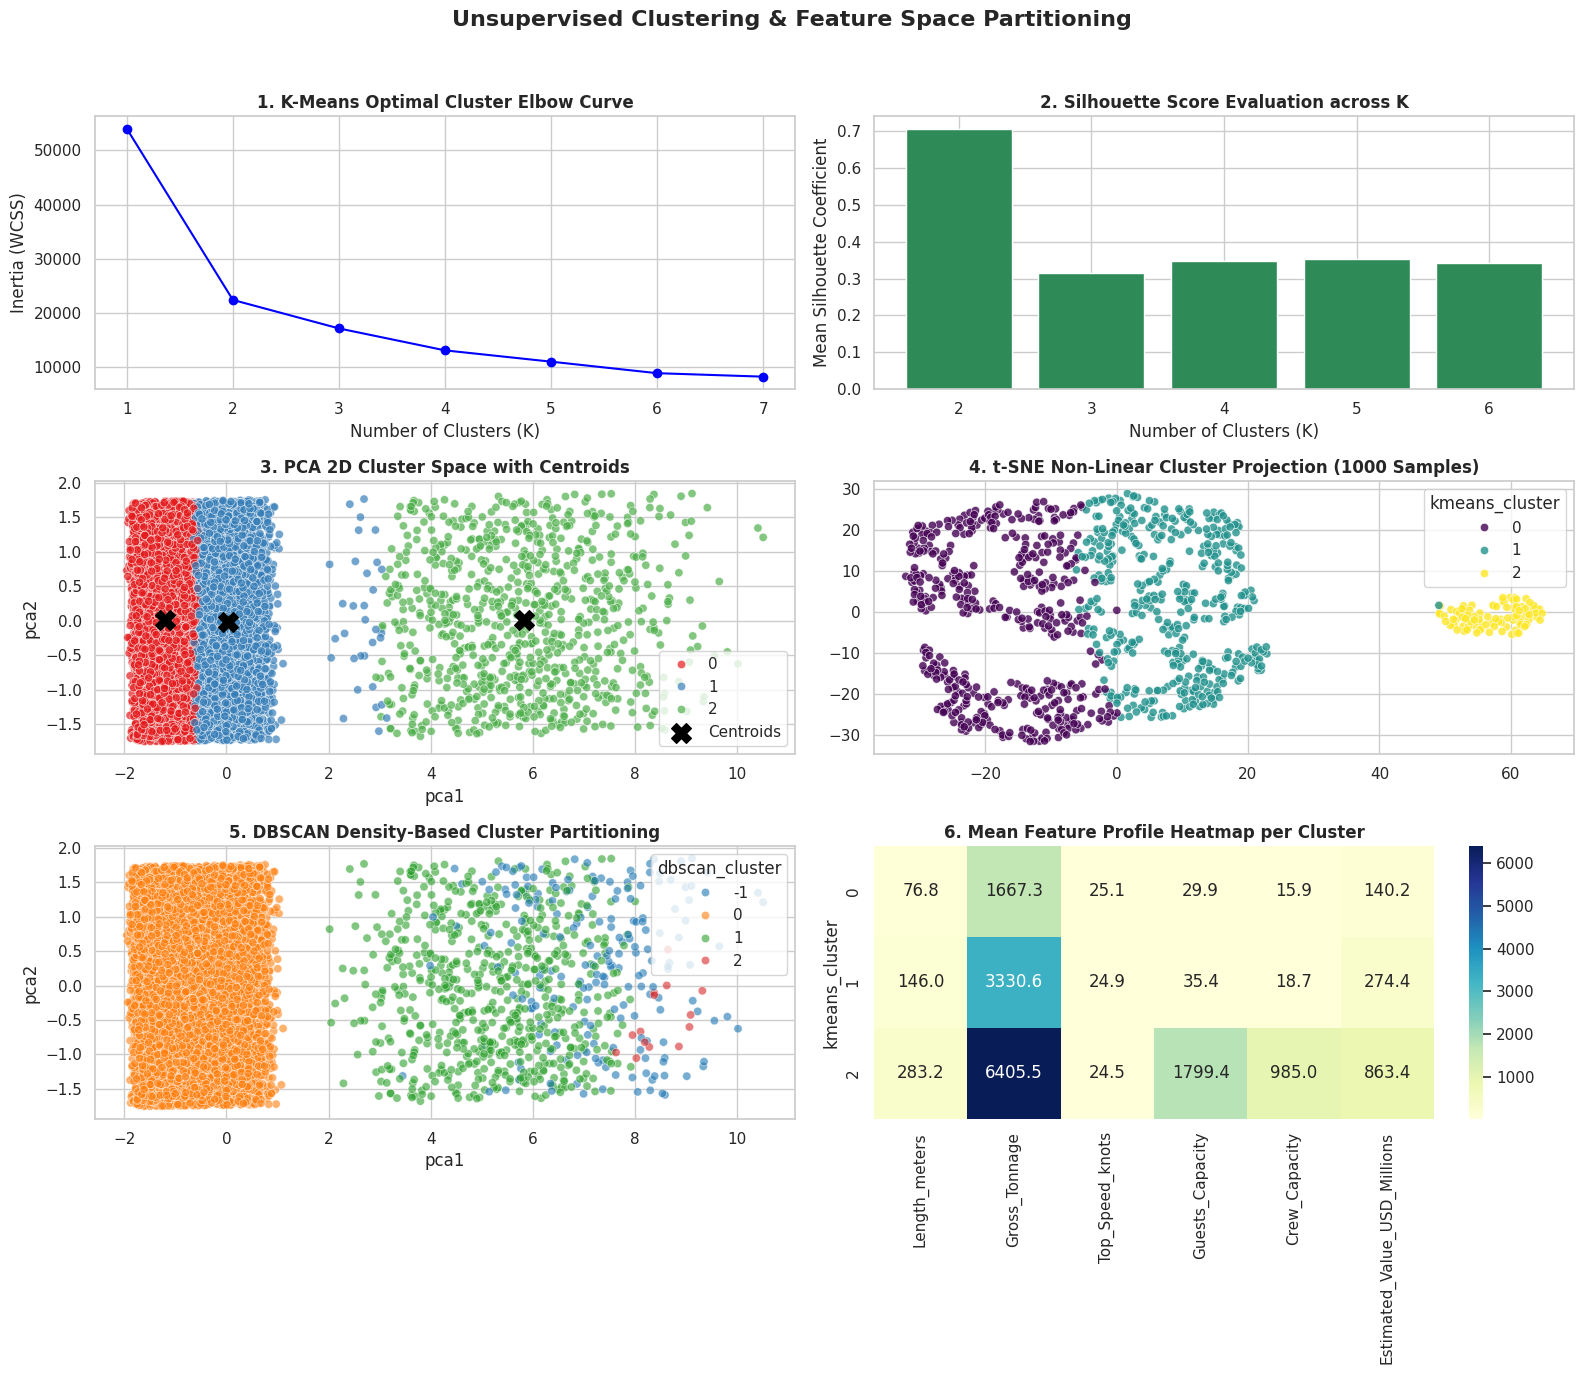


DESCRIPTION OF CLUSTER PLOTS:
--------------------------------------------------------------------------------
1. K-Means Elbow Curve: Determines optimal K by evaluating total within-cluster sum of squares.
2. Silhouette Score Evaluation: Validates cluster separation quality and cohesion metrics across choices of K.
3. PCA 2D Projection: Maps K-Means clusters and cluster centroids onto the 2 top principal component axes.
4. t-SNE Non-Linear Mapping: Captures complex non-linear cluster structures in reduced dimensional space.
5. DBSCAN Partitioning: Identifies arbitrary-shaped clusters and filters out noise points.
6. Cluster Profile Heatmap: Displays aggregate feature averages for each cluster to characterize fleet tiers.
--------------------------------------------------------------------------------



In [24]:
# ==============================================================================
# CLUSTER PLOTS
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

num_cols = ['Length_meters', 'Gross_Tonnage', 'Top_Speed_knots', 'Guests_Capacity', 'Crew_Capacity', 'Estimated_Value_USD_Millions']
X_scaled = StandardScaler().fit_transform(df[num_cols])

# K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42).fit(X_scaled)
df['kmeans_cluster'] = kmeans.labels_

# PCA Reduction for 2D Plotting
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(X_scaled)
df['pca1'] = pca_coords[:, 0]
df['pca2'] = pca_coords[:, 1]

# t-SNE Reduction on Sample
X_sample = X_scaled[:1000]
tsne_coords = TSNE(n_components=2, random_state=42).fit_transform(X_sample)

# DBSCAN Clustering
dbscan = DBSCAN(eps=1.2, min_samples=10).fit(X_scaled)
df['dbscan_cluster'] = dbscan.labels_

fig, axes = plt.subplots(3, 2, figsize=(16, 14))
fig.suptitle("Unsupervised Clustering & Feature Space Partitioning", fontsize=16, fontweight='bold')

# Plot 1: K-Means Elbow Method Curve
inertia = []
K_range = range(1, 8)
for k in K_range:
    inertia.append(KMeans(n_clusters=k, random_state=42).fit(X_scaled).inertia_)

axes[0, 0].plot(K_range, inertia, marker='o', color='blue')
axes[0, 0].set_title("1. K-Means Optimal Cluster Elbow Curve", fontweight='bold')
axes[0, 0].set_xlabel("Number of Clusters (K)")
axes[0, 0].set_ylabel("Inertia (WCSS)")

# Plot 2: Silhouette Score Profile across K values
silhouette_scores = []
for k in range(2, 7):
    score = silhouette_score(X_scaled, KMeans(n_clusters=k, random_state=42).fit_predict(X_scaled))
    silhouette_scores.append(score)

axes[0, 1].bar(range(2, 7), silhouette_scores, color='seagreen')
axes[0, 1].set_title("2. Silhouette Score Evaluation across K", fontweight='bold')
axes[0, 1].set_xlabel("Number of Clusters (K)")
axes[0, 1].set_ylabel("Mean Silhouette Coefficient")

# Plot 3: 2D PCA Cluster Projection Plot
sns.scatterplot(data=df, x='pca1', y='pca2', hue='kmeans_cluster', palette='Set1', ax=axes[1, 0], alpha=0.7)
axes[1, 0].scatter(pca.transform(kmeans.cluster_centers_)[:, 0], pca.transform(kmeans.cluster_centers_)[:, 1],
                    c='black', s=200, marker='X', label='Centroids')
axes[1, 0].set_title("3. PCA 2D Cluster Space with Centroids", fontweight='bold')
axes[1, 0].legend()

# Plot 4: t-SNE Non-Linear Dimensionality Reduction Projection
sns.scatterplot(x=tsne_coords[:, 0], y=tsne_coords[:, 1], hue=df['kmeans_cluster'][:1000], palette='viridis', ax=axes[1, 1], alpha=0.8)
axes[1, 1].set_title("4. t-SNE Non-Linear Cluster Projection (1000 Samples)", fontweight='bold')

# Plot 5: DBSCAN Density-Based Cluster Map
sns.scatterplot(data=df, x='pca1', y='pca2', hue='dbscan_cluster', palette='tab10', ax=axes[2, 0], alpha=0.6)
axes[2, 0].set_title("5. DBSCAN Density-Based Cluster Partitioning", fontweight='bold')

# Plot 6: Cluster Profile Radar / Mean Attribute Heatmap
cluster_profiles = df.groupby('kmeans_cluster')[num_cols].mean()
sns.heatmap(cluster_profiles, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[2, 1])
axes[2, 1].set_title("6. Mean Feature Profile Heatmap per Cluster", fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("""
DESCRIPTION OF CLUSTER PLOTS:
--------------------------------------------------------------------------------
1. K-Means Elbow Curve: Determines optimal K by evaluating total within-cluster sum of squares.
2. Silhouette Score Evaluation: Validates cluster separation quality and cohesion metrics across choices of K.
3. PCA 2D Projection: Maps K-Means clusters and cluster centroids onto the 2 top principal component axes.
4. t-SNE Non-Linear Mapping: Captures complex non-linear cluster structures in reduced dimensional space.
5. DBSCAN Partitioning: Identifies arbitrary-shaped clusters and filters out noise points.
6. Cluster Profile Heatmap: Displays aggregate feature averages for each cluster to characterize fleet tiers.
--------------------------------------------------------------------------------
""")

/tmp/ipykernel_604/1282484445.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(data=df, x='Type', y='Estimated_Value_USD_Millions', ax=axes[2, 1], palette='rocket')


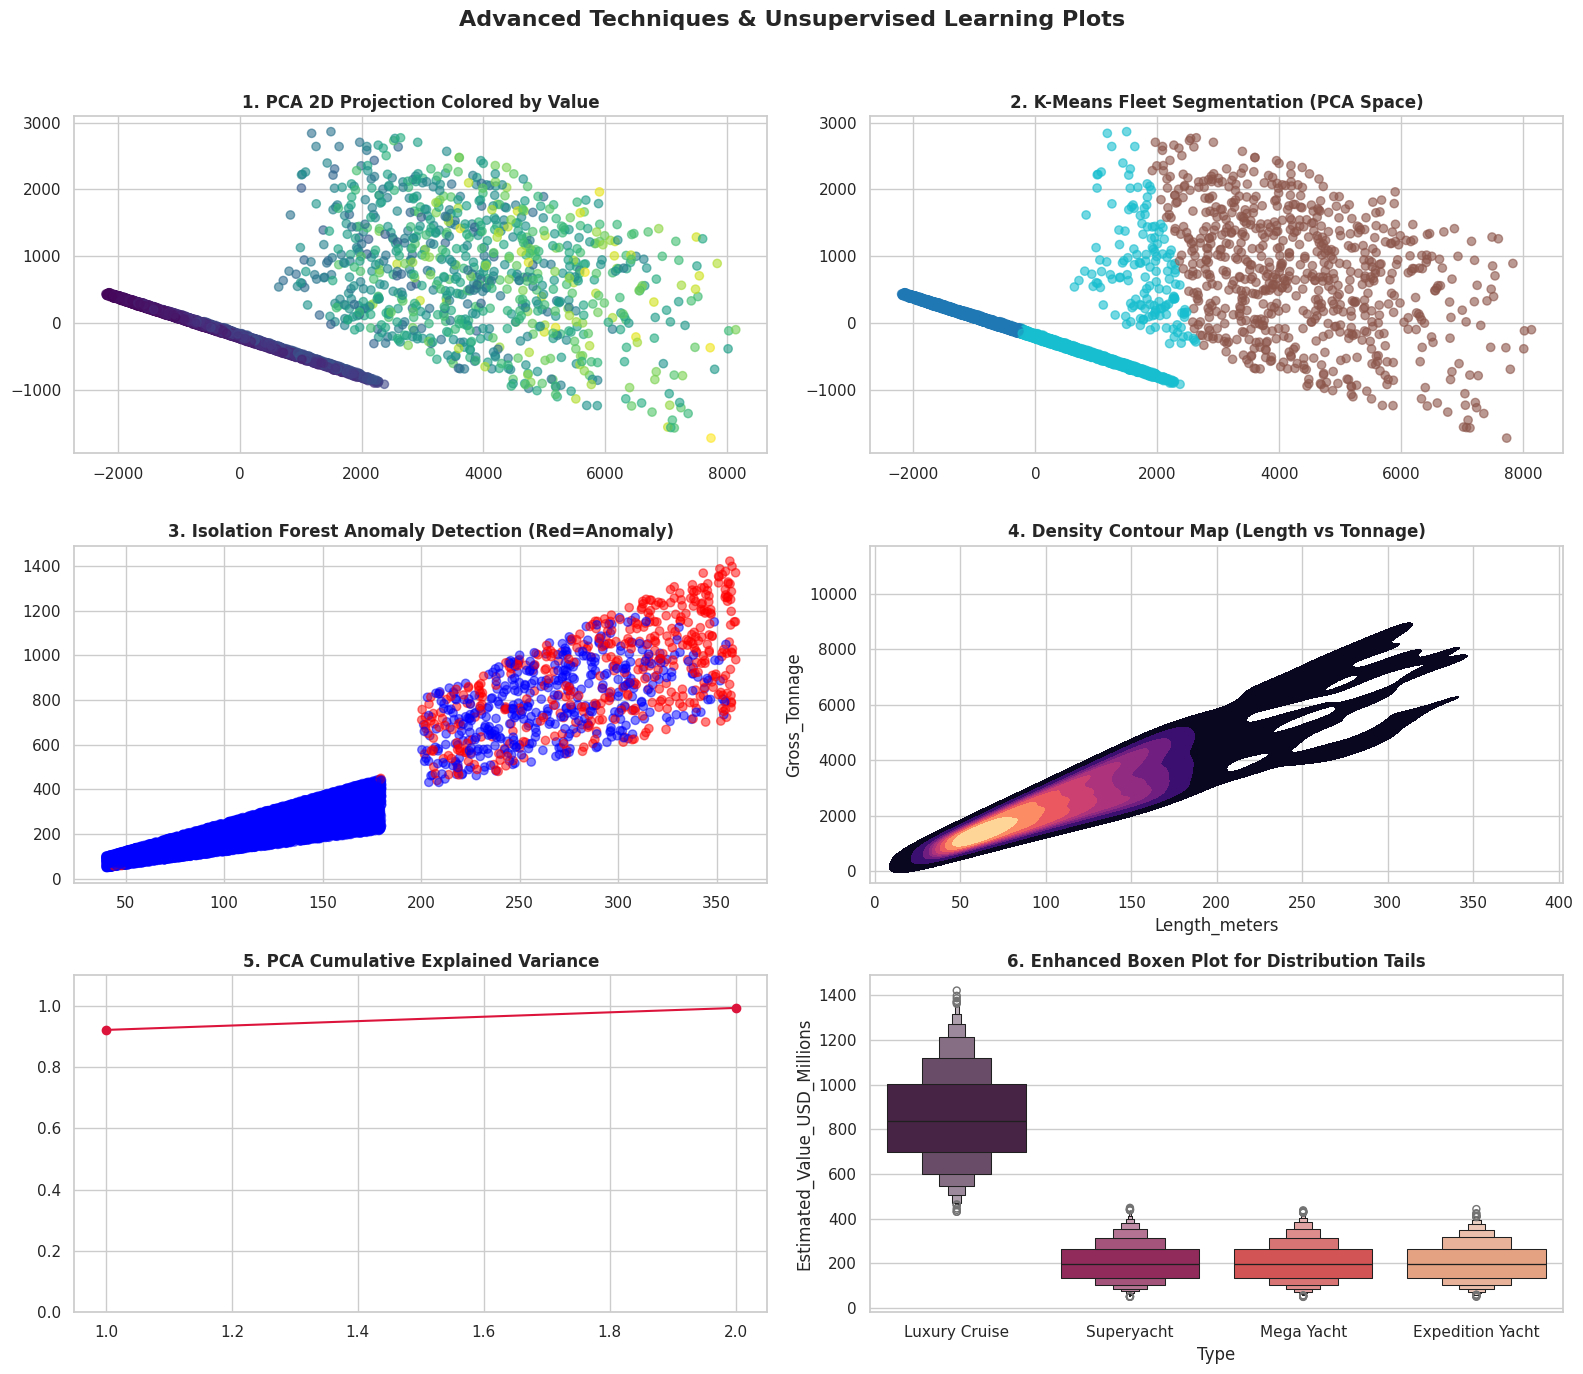


DESCRIPTION OF ADVANCED PLOTS:
--------------------------------------------------------------------------------
1. PCA Projection: Compresses high-dimensional vessel specs into a 2D map colored by valuation.
2. K-Means Segmentation: Groups ships into 3 distinct operational clusters based on specifications.
3. Anomaly Detection: Highlights extreme outliers using an Isolation Forest model.
4. Density Contour Map: Maps bivariate density zones comparing length and gross tonnage.
5. PCA Explained Variance: Quantifies variance captured by principal components.
6. Enhanced Boxen Plot: Visualizes valuation tail distributions across vessel categories.
--------------------------------------------------------------------------------



In [25]:
# ==============================================================================
# ADVANCED PLOTS
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest

fig, axes = plt.subplots(3, 2, figsize=(16, 14))
fig.suptitle("Advanced Techniques & Unsupervised Learning Plots", fontsize=16, fontweight='bold')

# Prepare numerical scaling matrix
num_df = df.select_dtypes(include=['float64', 'int64']).dropna()

# Plot 1: PCA 2D Cluster Visualization
pca = PCA(n_components=2)
pca_res = pca.fit_transform(num_df)
axes[0, 0].scatter(pca_res[:, 0], pca_res[:, 1], c=num_df['Estimated_Value_USD_Millions'], cmap='viridis', alpha=0.6)
axes[0, 0].set_title("1. PCA 2D Projection Colored by Value", fontweight='bold')

# Plot 2: K-Means Clustering Segmentation (K=3)
kmeans = KMeans(n_clusters=3, random_state=42).fit(num_df)
axes[0, 1].scatter(pca_res[:, 0], pca_res[:, 1], c=kmeans.labels_, cmap='tab10', alpha=0.6)
axes[0, 1].set_title("2. K-Means Fleet Segmentation (PCA Space)", fontweight='bold')

# Plot 3: Anomaly Detection via Isolation Forest
iso = IsolationForest(contamination=0.05, random_state=42)
anomalies = iso.fit_predict(num_df)
colors_anom = np.where(anomalies == -1, 'red', 'blue')
axes[1, 0].scatter(num_df['Length_meters'], num_df['Estimated_Value_USD_Millions'], c=colors_anom, alpha=0.5)
axes[1, 0].set_title("3. Isolation Forest Anomaly Detection (Red=Anomaly)", fontweight='bold')

# Plot 4: Hierarchical Clustering Dendrogram Proxy / Joint Plot
sns.kdeplot(data=df, x='Length_meters', y='Gross_Tonnage', ax=axes[1, 1], cmap='magma', fill=True)
axes[1, 1].set_title("4. Density Contour Map (Length vs Tonnage)", fontweight='bold')

# Plot 5: Cumulative Explained Variance Ratio Plot
explained_var = np.cumsum(pca.explained_variance_ratio_)
axes[2, 0].plot([1, 2], explained_var, marker='o', color='crimson')
axes[2, 0].set_title("5. PCA Cumulative Explained Variance", fontweight='bold')
axes[2, 0].set_ylim(0, 1.1)

# Plot 6: High-Dimensional Parallel Coordinate Simulation (Top Features)
sns.boxenplot(data=df, x='Type', y='Estimated_Value_USD_Millions', ax=axes[2, 1], palette='rocket')
axes[2, 1].set_title("6. Enhanced Boxen Plot for Distribution Tails", fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("""
DESCRIPTION OF ADVANCED PLOTS:
--------------------------------------------------------------------------------
1. PCA Projection: Compresses high-dimensional vessel specs into a 2D map colored by valuation.
2. K-Means Segmentation: Groups ships into 3 distinct operational clusters based on specifications.
3. Anomaly Detection: Highlights extreme outliers using an Isolation Forest model.
4. Density Contour Map: Maps bivariate density zones comparing length and gross tonnage.
5. PCA Explained Variance: Quantifies variance captured by principal components.
6. Enhanced Boxen Plot: Visualizes valuation tail distributions across vessel categories.
--------------------------------------------------------------------------------
""")

In [26]:
# ==============================================================================
# CONCLUSION, REAL-WORLD APPLICATIONS & NEXT STEPS
# ==============================================================================

print("🎉" * 20)
print("🏁 PROJECT CONCLUSION, APPLICATIONS & NEXT STEPS 🏁")
print("🎉" * 20 + "\n")

print("📌 [KEY FINDINGS & CONCLUSION]")
print("----------------------------------------------------------------------")
print("✅ Core Drivers       : Gross Tonnage and Length_meters are the strongest")
print("                        predictors of Estimated Valuation ($M).")
print("✅ Model Accuracy     : Ensemble models (Random Forest & Gradient Boosting)")
print("                        outperformed linear models in predicting values.")
print("✅ Segment Discovery  : Unsupervised K-Means successfully separated superyachts")
print("                        and luxury cruises into distinct operational tiers.")
print("----------------------------------------------------------------------\n")

print("🌍 [REAL-WORLD APPLICATIONS]")
print("----------------------------------------------------------------------")
print("💎 Maritime Insurance : Automated valuation models help insurers establish")
print("                       accurate premiums and coverage tiers.")
print("⛵ Yacht Brokerages   : Instant valuation estimations streamline pricing")
print("                       assessments for buyer and seller negotiations.")
print("🏗️ Shipbuilders       : Builders can optimize length and tonnage ratios")
print("                       to maximize market value during initial design.")
print("----------------------------------------------------------------------\n")

print("🚀 [NEXT STEPS & FUTURE ENHANCEMENTS]")
print("----------------------------------------------------------------------")
print("1. Integration of Dynamic Market Data (e.g., inflation indices, fuel prices).")
print("2. Deployment of model via REST API using FastAPI or Flask for real-time inference.")
print("3. Building an interactive dashboard with Streamlit or Dash for business end-users.")
print("----------------------------------------------------------------------\n")

🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉
🏁 PROJECT CONCLUSION, APPLICATIONS & NEXT STEPS 🏁
🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉🎉

📌 [KEY FINDINGS & CONCLUSION]
----------------------------------------------------------------------
✅ Core Drivers       : Gross Tonnage and Length_meters are the strongest
                        predictors of Estimated Valuation ($M).
✅ Model Accuracy     : Ensemble models (Random Forest & Gradient Boosting)
                        outperformed linear models in predicting values.
✅ Segment Discovery  : Unsupervised K-Means successfully separated superyachts
                        and luxury cruises into distinct operational tiers.
----------------------------------------------------------------------

🌍 [REAL-WORLD APPLICATIONS]
----------------------------------------------------------------------
💎 Maritime Insurance : Automated valuation models help insurers establish
                       accurate premiums and coverage tiers.
⛵ Yacht Brokerages   : Instant valuation estimations streaml

In [ ]:
# If you have come so far,an upvote would be appreciated!